# Detecting acute stress from wearable sensors (WESAD)

**Jillian Melbourne** · HSE.751, Fall 2026

An end-to-end, reproducible pipeline: raw chest and wrist signals → 60-second window features → validation and quality control → descriptive and inferential analysis → supervised classification of stress vs. non-stress, evaluated on participants the models have never seen.

**How to run:** choose **Runtime → Run all**. No uploads are needed: the first code cell fetches the project code and the saved feature table from GitHub. Use the **run settings** form in section 3 to upload your own feature table or to rebuild features from the raw WESAD files.

**Where the code lives.** The signal-processing and helper functions are in the `src/wesad/` package of the repository, so this notebook can focus on decisions and results:

| Module | Contents |
|---|---|
| `config.py` | `PipelineConfig`: every setting (window length, filters, quality thresholds) in one place |
| `loading.py` | loading and validating raw WESAD files and window-level feature tables |
| `features.py` | raw signals → one row per 60-second window, with quality flags |
| `analysis.py` | baseline normalization and effect sizes |
| `plots.py` | figure helpers (including the distribution and scatterplot-matrix figures) |

| # | Section |
|---|---|
| 1 | Dataset selection |
| 2 | Dataset overview and project plan |
| 3 | Setup and run settings |
| 4 | Data input and validation |
| 5 | Single-participant deep dive (raw signals) |
| 6 | Feature pipeline |
| 7 | Cohort overview and data quality |
| 8 | Descriptive statistics and feature distributions |
| 9 | Baseline normalization |
| 10 | Effect sizes |
| 11 | Inferential tests: paired tests, collinearity, conditional (fixed-effects) logistic regression |
| 12 | Model evaluation: logistic regression, elastic net, decision tree and SVM under leave-one-participant-out validation |
| 13 | Deep learning: multi-layer perceptron (MLP) and final model selection |
| 14 | Data quality notes |
| 15 | Summary and next steps |

## 1. Dataset selection

**Dataset:** WESAD (Wearable Stress and Affect Detection)
**Source:** UC Irvine Machine Learning Repository, https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection

This dataset was selected because it contains chest (ECG, EDA, respiration, temperature, EMG, acceleration) and wrist (blood volume pulse, EDA, temperature, acceleration) recordings from 15 participants during a lab stress protocol that includes stress and non-stress conditions. Stress is hard to measure beyond self-report yet has major health effects, and wearables offer a promising way to quantify it passively. This dataset combined with signal processing and machine learning techniques enable quantiative stress detection. 

| Requirement  | How WESAD meets it |
|---|---|
| Binary classification  | Stress (study label 2) vs. non-stress (baseline + amusement, labels 1 and 3) |
| ≥ 300 observations | Each observation is a 60-second window; ~65 per participant × 15 participants ≈ 1,000 |
| ≥ 10 predictors | Features engineered per window from both devices (heart rate, HRV, EDA, breathing rate, skin temperature, movement)

## 2. Dataset overview and project plan


**Dataset structure.** One pickle holds 10 signal arrays plus a label array, with no missing values. The chest arrays have 4,255,300 rows at 700 Hz. The wrist arrays have between 24,316 rows (EDA and temperature, 4 Hz) and 389,056 rows (BVP, 64 Hz). Every array works out to the same length in seconds, because the authors trimmed both devices to the same synced span. There is no timestamp column; time = row number ÷ sampling rate.

**Target variable.** The `label` array codes the protocol condition at 700 Hz. The binary target is stress (label 2) vs. non-stress (baseline 1 + amusement 3).

**Predictor variables.** There are six chest signals (ECG, EDA, respiration, temperature, EMG, 3-axis acceleration) and four wrist signals (BVP, EDA, temperature, 3-axis acceleration). Each 60-second window is summarized into 15 predictors (section 6):
- heart rate from chest ECG and wrist BVP
- heart rate variability (RMSSD) from chest ECG
- chest and wrist EDA level, chest EDA slope, count of wrist skin conductance responses
- breathing rate and breath-to-breath variability
- chest and wrist temperature, wrist temperature slope
- EMG amplitude (upper trapezius)
- movement variability on each device

Section 9 adds a **baseline-normalized** copy of every predictor (each person's values expressed relative to their own baseline).

### Project plan
- **Proposed prediction problem:** Detect physiological stress from wearable sensor data. Using chest (RespiBAN) and wrist (Empatica E4) recordings from the 15 WESAD participants, predict whether a person was under stress during a given 60-second window, using features engineered from heart rate, HRV, EDA, respiration, skin temperature, muscle activity and movement.
- **Target variable:** Binary stress, where 1 is stress (recorded during public speaking stress test; WESAD label 2) and 0 is non-stress (baseline and amusement; WESAD labels 1 and 3). Transitions, meditation, and "ignore" periods are excluded. Each observation is one 60-second window (30-second step), giving roughly 1,000 windows across all participants. 
- **Candidate evaluation metrics:** F1 score on the stress class as the primary metric, with AUROC as a supporting metric. Stress is a minority of the usable time, so accuracy would be misleading. Models will be evaluated with leave-one-subject-out cross-validation, because overlapping windows from the same person would otherwise leak between training and test sets and inflate performance.

## 3. Setup and run settings

### 3.1 Get the project code
When the notebook is opened on its own (for example from a Colab link), this cell downloads the repository from GitHub so the `src/wesad` package and the saved feature table are available. When the notebook is already inside the repository, it does nothing.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/JillianMelbourne/WESAD-Stress-Detection.git"
REPO_DIR = "WESAD-Stress-Detection"

if not Path("src/wesad").exists():                       # not running from inside the repository
    if not Path(REPO_DIR).exists():
        print(f"Downloading the project from {REPO_URL} ...")
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
if not Path("src/wesad").exists():
    raise FileNotFoundError(f"src/wesad was not found in {Path.cwd()}. The GitHub repository may not have "
                            "the latest version yet; push it, delete the downloaded folder, and run again.")
if str(Path("src").resolve()) not in sys.path:
    sys.path.insert(0, str(Path("src").resolve()))
print(f"Working directory: {Path.cwd()}")

Working directory: /Users/jmelb/Projects/Dartmouth_HDS/WESAD-Stress-Detection


### 3.2 Imports

In [2]:

import inspect
import platform
import textwrap
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy
import sklearn
import statsmodels
from scipy import stats
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

# scikit-learn: model pipelines, tuning and leave-one-participant-out evaluation (section 12)
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# statsmodels: conditional (fixed-effects) logistic regression (section 11.3)
from statsmodels.discrete.conditional_models import ConditionalLogit


In [3]:

from wesad import analysis, features, loading, plots
from wesad.config import (CONDITION_ORDER, EXCLUDE_FEATURES, README_NOTES, SUBJECTS,
                          PipelineConfig)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__} | "
      f"scikit-learn {sklearn.__version__} | statsmodels {statsmodels.__version__}")

Python 3.10.19 | numpy 2.2.6 | pandas 2.3.3 | scipy 1.15.3 | matplotlib 3.10.8 | scikit-learn 1.7.2 | statsmodels 0.15.0


### 3.3 Run settings
In Colab this cell shows as a form with drop-down menus. The defaults let **Run all** finish without any input.

| Setting | Options |
|---|---|
| `DATA_SOURCE` | **Use saved feature table** (default): the 1,015-window table for all 15 participants in `data/processed/`. <br>**Upload my own feature table**: a CSV with one row per window, a `subject` column, a 0/1 `stress` column and numeric feature columns (section 4 checks it). <br>**Rebuild from raw WESAD files**: re-runs feature extraction on the pickles in `data/raw/` (all 15 take a few minutes). |
| `UPLOAD_PATH` | Use to different CSV file. |
| `DEEP_DIVE_SUBJECT` | Participant shown in section 5. Needs that participant's raw file; skipped otherwise. |
| `SAVE_FIGURES` | Save every figure to `figures/` folder. |

Pipeline settings (window length, filter bands, quality thresholds) are fields of `PipelineConfig`; pass a different value here, e.g. `PipelineConfig(window_s=30)` or change settings within `config.py` within `src\wesad\`, and choose **Rebuild** to apply it.

In [4]:
DATA_SOURCE = "Use saved feature table"  # @param ["Use saved feature table", "Upload my own feature table", "Rebuild from raw WESAD files"]
UPLOAD_PATH = ""  # @param {type:"string"}
DEEP_DIVE_SUBJECT = "S2"  # @param ["S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S13", "S14", "S15", "S16", "S17"]
SAVE_FIGURES = True  # @param {type:"boolean"}

cfg = PipelineConfig(save_figures=SAVE_FIGURES)

# ---- check the settings before anything runs ---------------------------------
VALID_SOURCES = ["Use saved feature table", "Upload my own feature table", "Rebuild from raw WESAD files"]
if DATA_SOURCE not in VALID_SOURCES:
    raise ValueError(f"DATA_SOURCE must be one of {VALID_SOURCES}; got {DATA_SOURCE!r}")
if DEEP_DIVE_SUBJECT not in SUBJECTS:
    raise ValueError(f"DEEP_DIVE_SUBJECT must be one of {SUBJECTS}; got {DEEP_DIVE_SUBJECT!r}")
print(f"Data source: {DATA_SOURCE}")
print(f"Window: {cfg.window_s} s, step {cfg.step_s} s | target map (WESAD label -> stress): {cfg.target_map}")

Data source: Use saved feature table
Window: 60 s, step 30 s | target map (WESAD label -> stress): {1: 0, 3: 0, 2: 1}


## 4. Data input and validation

The cell below loads the feature table from the chosen source and adapts when something is missing:

- **Saved table:** read `data/processed/wesad_windows.csv`. If its recorded settings differ from `cfg`, a warning says so.
- **Upload:** open a file picker (Colab) or read `UPLOAD_PATH`.
- **Rebuild:** run the feature pipeline on the raw files. If no raw files are present, fall back to the saved table with a message instead of failing.

Every table, whatever its source, then goes through `validate_feature_table`, which checks for the required columns, a 0/1 target, enough windows in each class and at least two participants. It also drops (and reports) rows without a target and features that are mostly empty. A profile of every feature and a confirmation message follow.

In [5]:
def load_from_source(source):
    """Return (raw table, description of where it came from) for the chosen DATA_SOURCE."""
    if source == "Rebuild from raw WESAD files":
        present = [s for s in SUBJECTS if loading.raw_available(s, cfg)]
        if present:
            print(f"Rebuilding features from {len(present)} raw file(s) in {cfg.data_dir}/ ...")
            return features.build_feature_table(cfg, present), f"rebuilt from raw files ({len(present)} participants)"
        print(f"No raw WESAD files found in {cfg.data_dir}/, so falling back to the saved feature table.")
        source = "Use saved feature table"

    if source == "Upload my own feature table":
        path = Path(UPLOAD_PATH) if UPLOAD_PATH else loading.upload_feature_table()
        if not path.exists():
            raise FileNotFoundError(f"UPLOAD_PATH {path} does not exist.")
        return pd.read_csv(path), f"uploaded file {path.name}"

    if not cfg.feature_table.exists():
        raise FileNotFoundError(f"{cfg.feature_table} is missing. Re-download the repository or choose another DATA_SOURCE.")
    if features.saved_settings_match(cfg) is False:
        print("Warning: the saved table was built with different settings from cfg. "
              "Choose 'Rebuild from raw WESAD files' to apply the current settings.")
    return pd.read_csv(cfg.feature_table), f"saved table {cfg.feature_table}"


table, source_note = load_from_source(DATA_SOURCE)
feats, FEATURES, notes = loading.validate_feature_table(table)   # raises with a full list of problems if invalid
for note in notes:
    print("Note:", note)

# Is this the WESAD pipeline's own output? Several later steps (readme notes, quality flags, conditions) depend on it.
IS_WESAD_TABLE = set(features.FEATURE_COLUMNS) <= set(feats.columns) and "condition" in feats.columns
HAS_FLAGS = "flag_any" in feats.columns

print(f"\n✅ Dataset loaded and validated ({source_note}): {len(feats):,} windows, {len(FEATURES)} features, "
      f"{feats['subject'].nunique()} participants, {feats['stress'].mean():.0%} stress windows.")


✅ Dataset loaded and validated (saved table data/processed/wesad_windows.csv): 1,015 windows, 15 features, 15 participants, 30% stress windows.


### 4.1 Data profile
One row per feature: data type, share missing, and range. Missing values are expected in two places in the WESAD table: chest temperature for S2 and S17 (excluded on purpose, see section 7) and occasional windows where too few heartbeats were detected.

In [6]:
display(loading.profile_table(feats, FEATURES))

,dtype,% missing,mean,sd,min,max
feature,,,,,,
chest_hr_bpm,float64,0.000,79.837,18.147,50.589,148.737
chest_rmssd_ms,float64,0.000,51.422,34.149,2.243,202.532
wrist_hr_bpm,float64,0.000,79.321,12.094,55.858,142.373
chest_eda_uS,float64,0.000,4.584,3.434,0.636,19.969
chest_eda_slope_uS_per_min,float64,0.000,0.006,0.316,-3.393,5.652
wrist_eda_uS,float64,0.000,1.965,2.653,0.094,15.612
wrist_scr_count,int64,0.000,8.810,8.160,0.000,45.000
resp_rate_bpm,float64,0.000,16.167,2.635,9.000,25.000
resp_interval_sd_s,float64,0.000,0.872,0.531,0.139,3.262


## 5. Single-participant deep dive (raw signals)

Sections 5.1–5.4 look at one participant's raw recording (`DEEP_DIVE_SUBJECT`, S2 by default) to show what the features are made from. They need that participant's raw file at `data/raw/<subject>/<subject>.pkl`. If it is not there, these cells print a note and the rest of the notebook runs normally.

In [7]:
DEEP_DIVE = loading.raw_available(DEEP_DIVE_SUBJECT, cfg)
if DEEP_DIVE:
    subj = loading.load_subject(DEEP_DIVE_SUBJECT, cfg)          # validated on load
    sig = features.preprocess(subj, cfg)
    win = features.extract_windows(subj, cfg, sig)
    periods = plots.condition_periods(subj["label"])
    print(f"Loaded {DEEP_DIVE_SUBJECT}: passed validation; {len(win)} windows")
else:
    print(f"Skipping section 5: no raw file for {DEEP_DIVE_SUBJECT} in {cfg.data_dir}/. "
          f"To include it, download WESAD from UCI and place {DEEP_DIVE_SUBJECT}.pkl at "
          f"{cfg.data_dir / DEEP_DIVE_SUBJECT / (DEEP_DIVE_SUBJECT + '.pkl')}.")

Loaded S2: passed validation; 65 windows


### 5.1 Recording structure
Each pickle is a nested dictionary: `label` (one condition code per 700 Hz sample) and `signal`, with six chest channels (RespiBAN, all 700 Hz) and four wrist channels (Empatica E4, 4–64 Hz). There is **no time column**: `seconds = row number / sampling rate`, and the authors trimmed both devices so row 0 of every array is temporally aligned.

In [8]:
if DEEP_DIVE:
    display(loading.describe_recording(subj))

,device,channel,shape,fs_Hz,duration_min,units,n_NaN
0,chest,ACC,"(4255300, 3)",700,101.317,g,0
1,chest,ECG,"(4255300, 1)",700,101.317,mV,0
2,chest,EMG,"(4255300, 1)",700,101.317,mV,0
3,chest,EDA,"(4255300, 1)",700,101.317,µS,0
4,chest,Temp,"(4255300, 1)",700,101.317,°C,0
5,chest,Resp,"(4255300, 1)",700,101.317,%,0
6,wrist,ACC,"(194528, 3)",32,101.317,g,0
7,wrist,BVP,"(389056, 1)",64,101.317,a.u.,0
8,wrist,EDA,"(24316, 1)",4,101.317,µS,0
9,wrist,TEMP,"(24316, 1)",4,101.317,°C,0


### 5.2 Target variable
| `stress` | WESAD label | Condition |
|---|---|---|
| **1** | 2 | Stress: Trier Social Stress Test (public speech + mental arithmetic) |
| **0** | 1, 3 | Baseline (reading magazines) and amusement (funny videos) |
| excluded | 0, 4, 5–7 | Transitions, meditation, and "ignore" periods |

In [9]:
if DEEP_DIVE:
    display(loading.target_summary(subj["label"], cfg))

,condition,minutes,% of recording,binary target
label,,,,
0,transient,51.017,50.354,excluded
1,baseline,19.067,18.819,0 (non-stress)
2,stress,10.250,10.117,1 (stress)
3,amusement,6.033,5.955,0 (non-stress)
4,meditation,12.800,12.634,excluded
6,ignore,1.083,1.069,excluded
7,ignore,1.067,1.053,excluded


### 5.3 Figures 1–2: raw signals
**Figure 1** shows the whole session with conditions shaded (white gaps are transitions or ignored periods). **Figure 2** shows the same 10 seconds of chest ECG and wrist BVP one minute into baseline and into stress; each heartbeat should be followed a fraction of a second later by a pulse at the wrist.

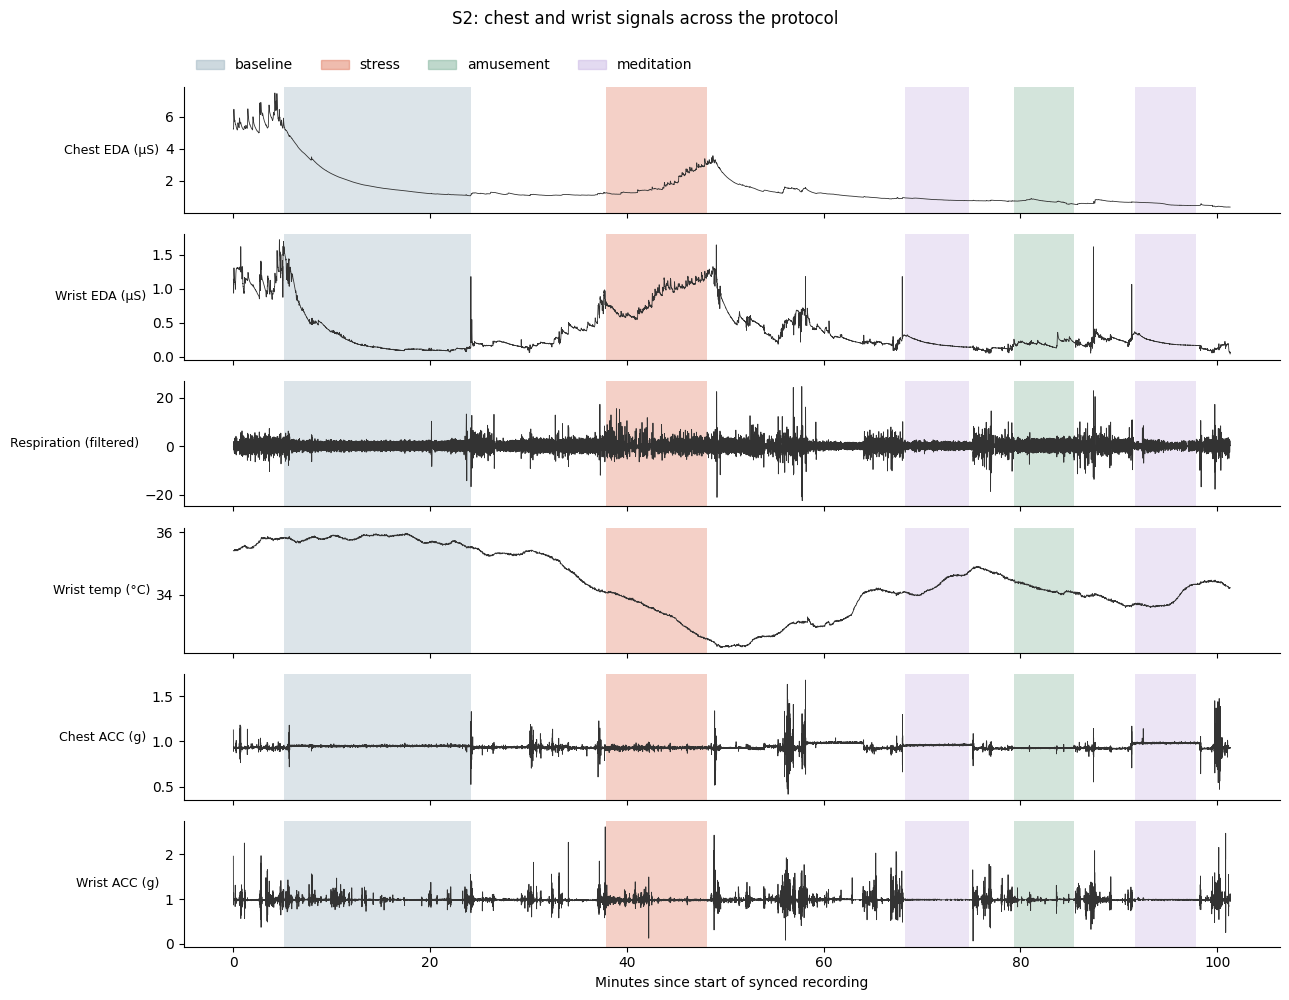

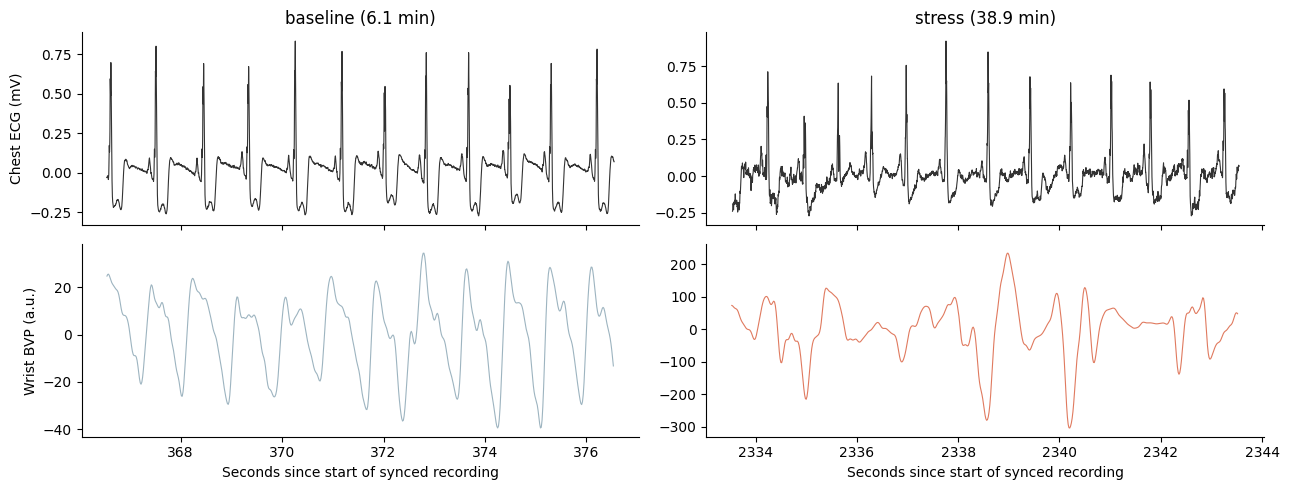

In [10]:
if DEEP_DIVE:
    fig = plots.aligned_session(sig, periods, DEEP_DIVE_SUBJECT)
    plots.save_fig(fig, f"fig1_{DEEP_DIVE_SUBJECT}_aligned_session", cfg)
    plt.show()
    fig = plots.ecg_vs_bvp(subj)
    plots.save_fig(fig, f"fig2_{DEEP_DIVE_SUBJECT}_ecg_vs_bvp", cfg)
    plt.show()

**What Figures 1–2 show (S2).** In Figure 1, skin conductance (EDA) on both devices falls steadily through baseline as the participant settles after the sensors are attached, then climbs throughout the stress task, peaks at its end and recovers afterwards. Wrist temperature drops by about 1.5 °C across the stress task (peripheral vasoconstriction: blood is diverted away from the hands) and takes about 20 minutes to recover. Breathing is more irregular during the stress task, when the participant is speaking. The accelerometers show bursts mainly at the transitions between conditions, when participants walk between rooms, rather than within conditions. In Figure 2 the ECG is clean and each R-peak is followed by a wrist pulse at baseline. During stress the ECG is noisier (muscle activity while speaking) and the wrist BVP waveform is distorted, with large swings in amplitude. This is why wrist heart rate is less reliable during the stress task, and why windows where chest and wrist heart rate disagree are flagged.

### 5.4 Figures 3–4: window features
**Figure 3:** each dot is one 60-second window; hollow dots carry at least one quality flag (section 6). **Figure 4:** feature distributions by condition.

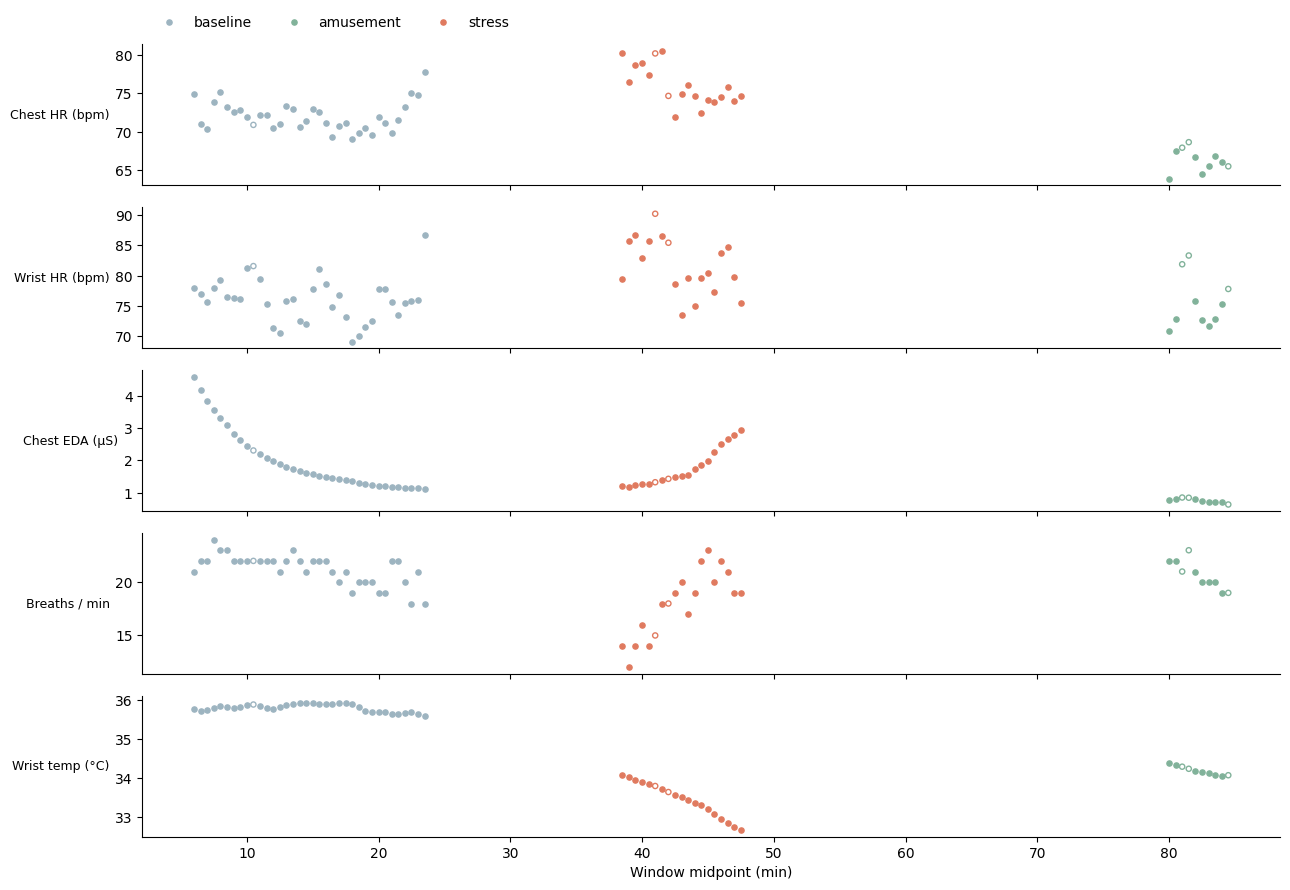

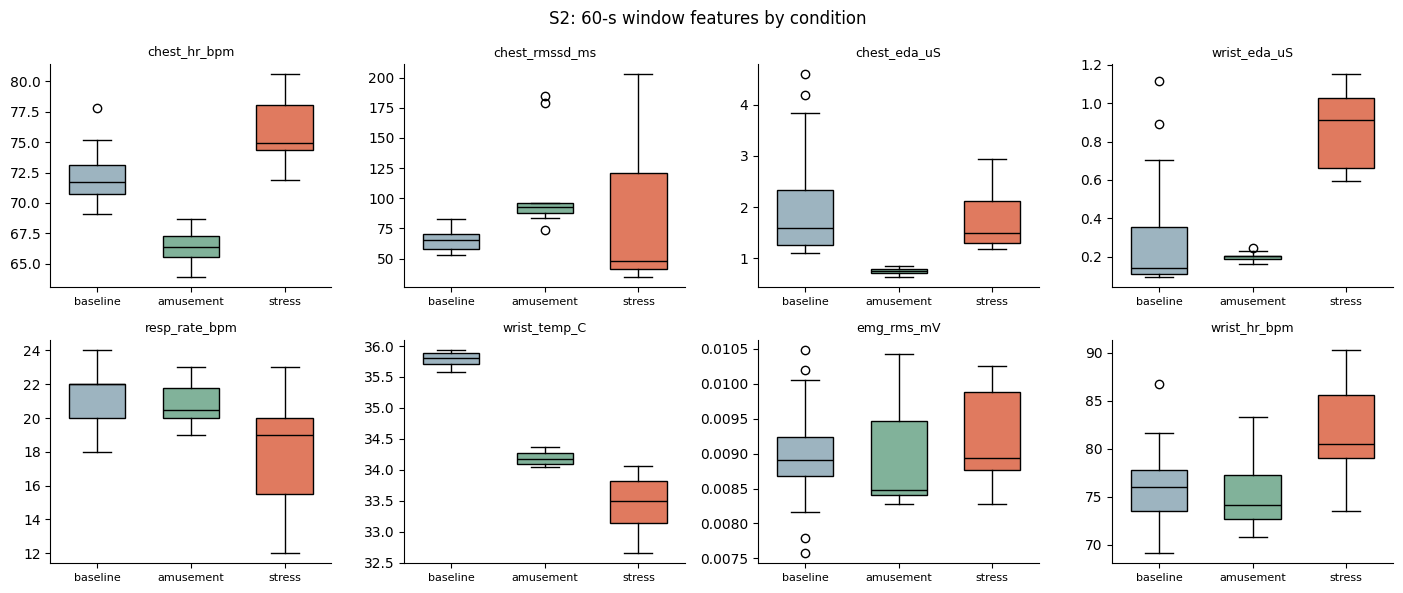

In [11]:
if DEEP_DIVE:
    fig = plots.features_over_time(win, [("chest_hr_bpm", "Chest HR (bpm)"), ("wrist_hr_bpm", "Wrist HR (bpm)"),
                                         ("chest_eda_uS", "Chest EDA (µS)"), ("resp_rate_bpm", "Breaths / min"),
                                         ("wrist_temp_C", "Wrist temp (°C)")])
    plots.save_fig(fig, f"fig3_{DEEP_DIVE_SUBJECT}_features_over_time", cfg)
    plt.show()
    fig = plots.condition_boxplots(win, ["chest_hr_bpm", "chest_rmssd_ms", "chest_eda_uS", "wrist_eda_uS",
                                         "resp_rate_bpm", "wrist_temp_C", "emg_rms_mV", "wrist_hr_bpm"],
                                   f"{DEEP_DIVE_SUBJECT}: 60-s window features by condition")
    plots.save_fig(fig, f"fig4_{DEEP_DIVE_SUBJECT}_feature_distributions", cfg)
    plt.show()

**What Figures 3–4 show (S2).** In Figure 3, heart rate on both devices jumps at the start of the stress task and drifts down across it, chest EDA falls through baseline and rises steeply through stress, breathing rate dips at the start of the stress task (preparing and starting the speech) before recovering, and wrist temperature falls continuously during stress. Only a handful of windows are flagged (hollow dots), mostly for chest–wrist heart-rate disagreement. In Figure 4, stress is clearly separated from baseline for heart rate (chest and wrist), wrist EDA and wrist temperature, while RMSSD and EMG overlap heavily across conditions. Two details matter for interpretation: amusement is not simply in between baseline and stress (for S2 it has the lowest heart rate and EDA of all three conditions), and S2's chest EDA is about as high at baseline as during stress because of the early settling-in decline seen in Figure 1. Absolute levels can therefore mislead within a session, which is one reason the analysis compares each person's stress windows with their own resting level.

## 6. Feature pipeline

`src/wesad/features.py` turns each participant's raw recording into one row per **60-second window** (30-second step):

1. `preprocess`: filters each whole recording once (zero-phase Butterworth filters) and downsamples where that loses nothing.
2. `window_features`: computes the predictors for one window.
3. `extract_windows`: slides the window across the recording, keeps windows whose label is in `target_map` and at least `min_label_purity` pure, sets channels listed in `EXCLUDE_FEATURES` to missing, and adds quality flags.
4. `build_feature_table`: runs every participant one at a time (each raw file is ~1 GB), skips any that are missing or fail validation, and saves the table with the settings used.

| Predictor | Source | Definition |
|---|---|---|
| `chest_hr_bpm`, `chest_rmssd_ms` | Electrocardiogram (ECG) | Mean HR and RMSSD from R-peaks (HRV) |
| `wrist_hr_bpm` | Blood Volume Pulse (BVP) | Mean HR from pulse peaks |
| `chest_eda_uS`, `chest_eda_slope_uS_per_min` | Chest Electrodermal Activity (EDA) | Mean level and linear trend of skin conductance|
| `wrist_eda_uS`, `wrist_scr_count` | Wrist Electrodermal Activity (EDA) | Mean level and number of skin conductance responses |
| `resp_rate_bpm`, `resp_interval_sd_s` | Resp | Breaths per minute and SD of breath-to-breath intervals |
| `chest_temp_C`, `wrist_temp_C`, `wrist_temp_slope_C_per_min` | Temp | Mean temperatures and wrist trend |
| `emg_rms_mV` | Electromyography (EMG) | RMS amplitude after a 20 Hz high-pass |
| `chest_acc_sd_g`, `wrist_acc_sd_g` | Accelerometer (ACC) | SD of acceleration magnitude (movement) |

| Quality flag | Rule | Likely cause |
|---|---|---|
| `flag_hr_missing` | chest or wrist HR missing (too few valid beats) | electrode or optical signal lost |
| `flag_hr_disagree` | chest and wrist HR differ by more than 10 bpm | BVP motion artifact |
| `flag_ecg_artifact` | more than 20% of chest beat intervals implausible | noisy ECG |
| `flag_temp_range` | skin temperature outside 25–40 °C | sensor detached |
| `flag_eda_contact` | wrist EDA below 0.05 µS | electrodes not touching the skin |

The core of the feature step, for reference:

In [12]:
print(inspect.getsource(features.window_features))

def window_features(sig, t0, cfg: PipelineConfig):
    """All predictors for the window starting at t0 seconds, plus two beat-rejection rates used for QC."""
    w = cfg.window_s
    max_hr = cfg.hr_range_bpm[1]
    e = cut(sig, "ecg_energy", t0, w)
    pk, _ = signal.find_peaks(e, distance=int(60 / max_hr * FS_CHEST), height=0.3 * np.percentile(e, 99))
    b = cut(sig, "bvp", t0, w)
    bpk, _ = signal.find_peaks(b, distance=int(60 / max_hr * 64), prominence=0.3 * b.std())
    r = cut(sig, "resp", t0, w)
    rpk, _ = signal.find_peaks(r, distance=15, prominence=0.3 * r.std())
    breath_iv = np.diff(rpk) / 10
    we, ce, wt = cut(sig, "wrist_eda", t0, w), cut(sig, "chest_eda", t0, w), cut(sig, "wrist_temp", t0, w)
    scr, _ = signal.find_peaks(we, prominence=0.01, distance=4)
    hr_c, rmssd_c, rej_c = beats_to_hr(pk, FS_CHEST, cfg)
    hr_w, _, rej_w = beats_to_hr(bpk, 64, cfg)       # wrist RMSSD is not used: 64 Hz pulse timing is too coarse
    return {
        "chest_hr_bpm": hr_

## 7. Cohort overview and data quality
Windows per participant and condition, the share of windows with each quality flag, and notes from each participant's readme. Flagged windows are kept but marked so later steps can drop them or test their influence.

In [13]:
group_col = "condition" if "condition" in feats.columns else "stress"
cohort = feats.groupby("subject")[group_col].value_counts().unstack(fill_value=0)
cohort = cohort.reindex(analysis.subject_order(feats["subject"]))
if group_col == "condition":
    cohort = cohort.reindex(columns=[c for c in CONDITION_ORDER if c in cohort.columns])
cohort["total"] = cohort.sum(axis=1)
cohort["% stress"] = 100 * feats.groupby("subject")["stress"].mean().reindex(cohort.index)
if HAS_FLAGS:                                   # quality flags only exist in tables built by this pipeline
    flag_cols = [c for c in features.FLAG_COLUMNS + ["flag_any"] if c in feats.columns]
    pct = feats.groupby("subject")[flag_cols].mean().mul(100).reindex(cohort.index)
    cohort = cohort.join(pct.rename(columns=lambda c: "% " + c.replace("flag_", "")))
if IS_WESAD_TABLE:
    cohort["readme note"] = [README_NOTES.get(s, "") + (" Chest temp excluded." if s in EXCLUDE_FEATURES else "")
                             for s in cohort.index]
display(cohort)
if HAS_FLAGS:
    print(f"{feats['flag_any'].mean():.0%} of windows carry at least one quality flag; "
          f"most come from chest-wrist heart-rate disagreement.")

,baseline,amusement,stress,total,% stress,% hr_missing,% hr_disagree,% ecg_artifact,% temp_range,% eda_contact,% any,readme note
subject,,,,,,,,,,,,
S2,36,10,19,65,29.231,0.000,9.231,0.000,0.000,0.000,9.231,Chest temp excluded.
S3,36,11,20,67,29.851,0.000,43.284,0.000,0.000,0.000,43.284,Baseline recorded in a sunny workplace (skin t...
S4,37,10,19,66,28.788,0.000,4.545,0.000,0.000,0.000,4.545,
S5,38,10,19,67,28.358,0.000,19.403,0.000,0.000,0.000,19.403,May have fallen asleep during the first medita...
S6,37,10,20,67,29.851,0.000,2.985,0.000,0.000,0.000,2.985,Reported the TSST interview was not really str...
S7,37,11,19,67,28.358,0.000,14.925,0.000,0.000,0.000,14.925,
S8,37,10,21,68,30.882,0.000,14.706,0.000,0.000,0.000,14.706,Stressful day before the study; felt cold in t...
S9,37,10,19,66,28.788,0.000,1.515,0.000,0.000,0.000,1.515,Reported feeling ill on the study day.
S10,37,10,22,69,31.884,0.000,17.391,0.000,0.000,0.000,17.391,


17% of windows carry at least one quality flag; most come from chest-wrist heart-rate disagreement.


## 8. Descriptive statistics and feature distributions
Mean of each feature by condition (or by stress label for an uploaded table without conditions), plus the share of windows where the feature is missing.

In [14]:
desc = feats.groupby(group_col)[FEATURES].mean().T
if group_col == "condition":
    desc = desc[[c for c in CONDITION_ORDER if c in desc.columns]]
desc["% missing"] = 100 * feats[FEATURES].isna().mean()
display(desc)

condition,baseline,amusement,stress,% missing
chest_hr_bpm,72.357,72.539,97.402,0.000
chest_rmssd_ms,52.734,56.229,46.518,0.000
wrist_hr_bpm,74.795,74.892,89.955,0.000
chest_eda_uS,3.885,4.477,5.926,0.000
chest_eda_slope_uS_per_min,-0.043,-0.011,0.103,0.000
wrist_eda_uS,1.320,1.410,3.442,0.000
wrist_scr_count,6.352,5.346,15.132,0.000
resp_rate_bpm,16.136,17.154,15.712,0.000
resp_interval_sd_s,0.637,0.808,1.337,0.000
chest_temp_C,33.797,34.274,34.365,13.202


### 8.1 Feature distributions by condition
**Figure 5** overlays the distribution of every feature for baseline, amusement and stress windows (all participants, all windows). Histograms are scaled to the same area so the three conditions compare fairly even though there are about 3.5 times as many baseline windows as amusement windows. The table below gives the skewness of each feature within each condition: 0 is symmetric, positive values mean a long right tail, and |skewness| > 1 is usually considered strongly skewed.

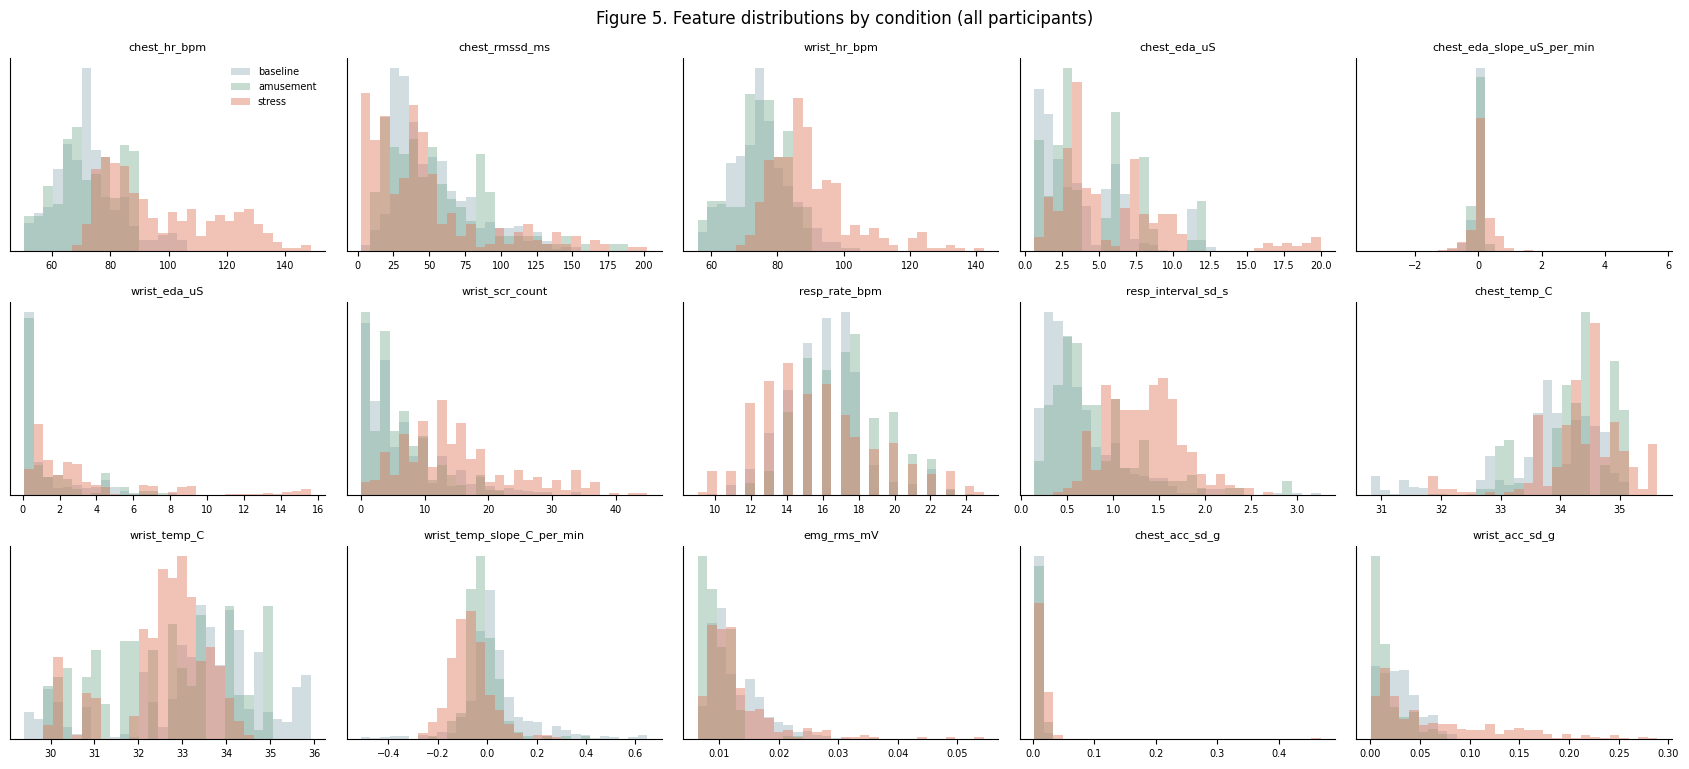

In [15]:
if "condition" in feats.columns:
    fig = plots.condition_histograms(feats, FEATURES, "Figure 5. Feature distributions by condition (all participants)")
    plots.save_fig(fig, "fig5_cohort_histograms", cfg)
    plt.show()
else:
    print("No `condition` column in this table, so the per-condition figures are skipped.")



**What Figure 5 shows.** Pooled across participants, most features are **right-skewed**: most windows have low values and a long tail of high ones. The strongest cases are wrist EDA, EMG, wrist movement, chest EDA slope, and chest movement. Chest temperature is the main **left-skewed** feature, and breathing rate is roughly symmetric but takes whole-number steps (breaths per 60-second window). Wrist temperature is **multimodal**: each peak is a different participant, showing that differences *between people* dominate the raw distributions. Stress windows (orange) are shifted to the right for heart rate, SCR count, breathing irregularity and EDA, and to the left for wrist temperature, while amusement largely overlaps baseline. Chest heart rate under stress is **bimodal**, with a second cluster at 110–140 bpm that wrist heart rate does not show. The skewness and the between-person clusters motivate two later steps: baseline normalization (section 9) and the Yeo–Johnson check before regression (section 11.3).

### 8.2 Box plots by condition
**Figure 6** shows the same features as box plots: the box spans the middle 50% of windows, the line is the median, whiskers reach 1.5 × the interquartile range, and circles are windows beyond that.

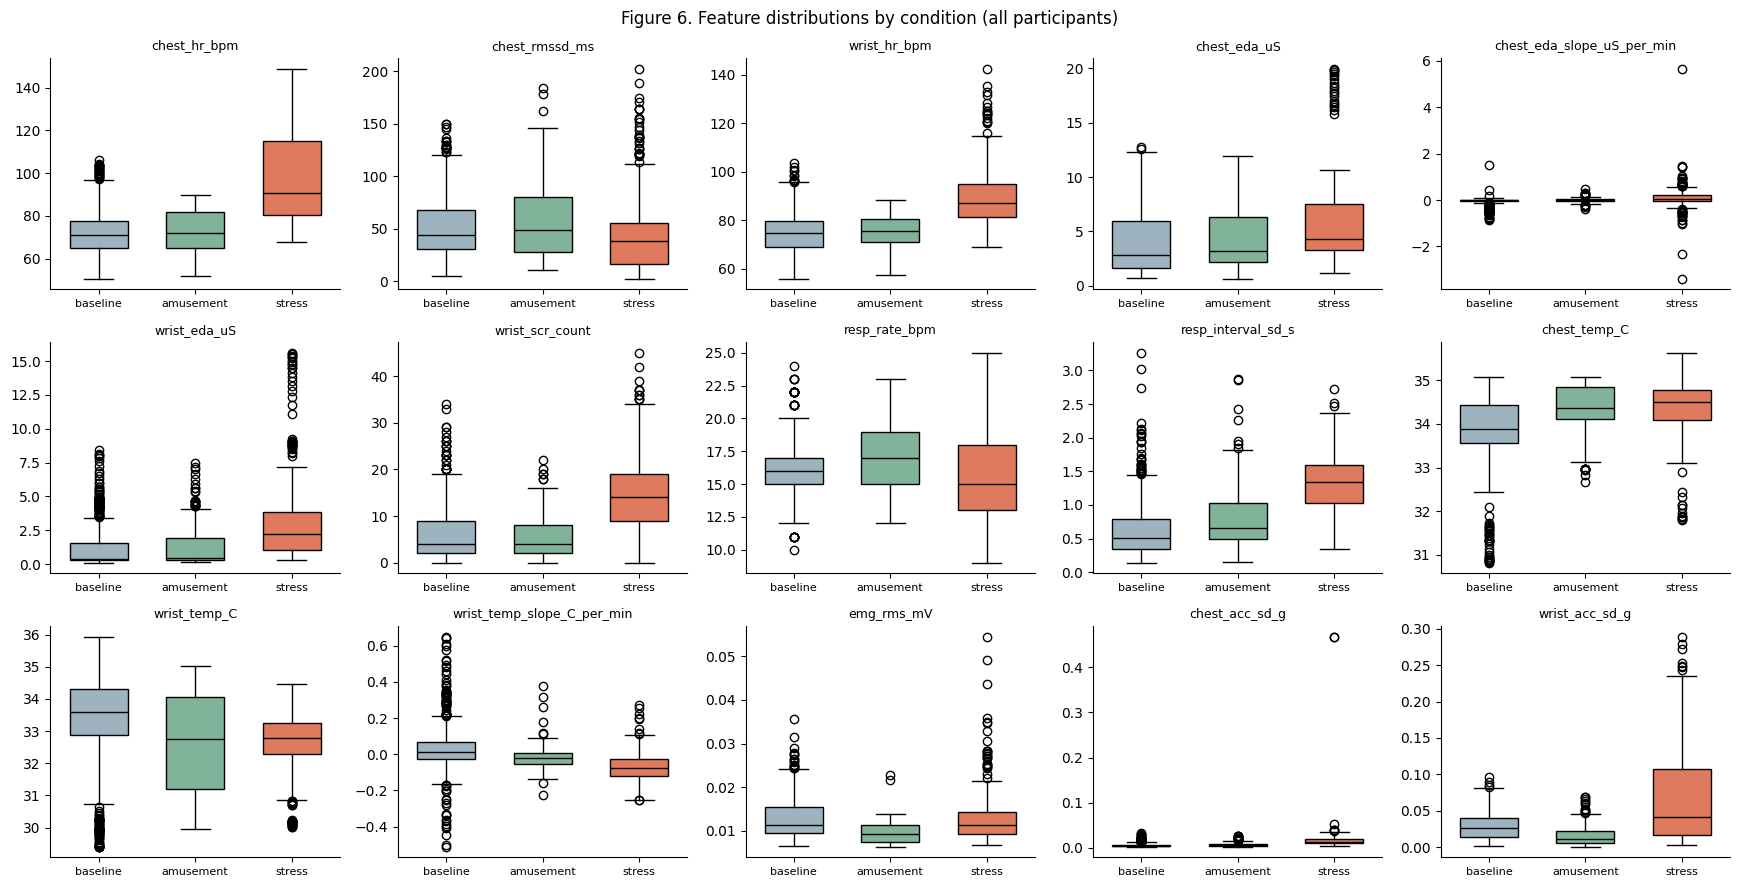

In [16]:
if "condition" in feats.columns:
    fig = plots.condition_boxplots(feats, FEATURES, "Figure 6. Feature distributions by condition (all participants)", ncols=5)
    plots.save_fig(fig, "fig6_cohort_boxplots", cfg)
    plt.show()

**What Figure 6 shows.** The median stress window has a higher chest heart rate (about 91 vs 72 bpm at baseline), higher wrist heart rate (about 87 vs 75 bpm), more skin conductance responses (about 14 vs 4 per minute), more irregular breathing (breath-interval SD about 1.35 vs 0.5 s), more wrist movement and a lower wrist temperature (about 32.8 vs 33.6 °C). For EDA level the stress boxes are higher, but they overlap the other conditions heavily, because people differ so much in their resting skin conductance. Breathing rate, EMG and RMSSD boxes overlap almost completely, so they separate the conditions poorly. Chest EDA slope and chest movement have very narrow boxes with many outliers: most windows are near zero and a few are extreme, which matches their high skewness. Amusement looks like baseline for most features, so in this protocol the main contrast is between the stress task and everything else. Many of the circles beyond the whiskers (for example the cool baseline temperatures) come from individual differences between participants and are within physiologically plausible bounds.

### 8.3 Pairwise relationships (scatterplot matrix)
**Figure 7** is a scatterplot matrix: every panel below the diagonal plots one feature against another (one dot per window, coloured by condition), and the diagonal shows each feature's distribution. It shows at a glance which features rise together (a diagonal cloud), which are unrelated (a round cloud), and whether a relationship is straight or curved. Fifteen features would need 105 panels, so the matrix uses seven features chosen to cover each body system and to include the pairs flagged as overlapping in section 11.2.

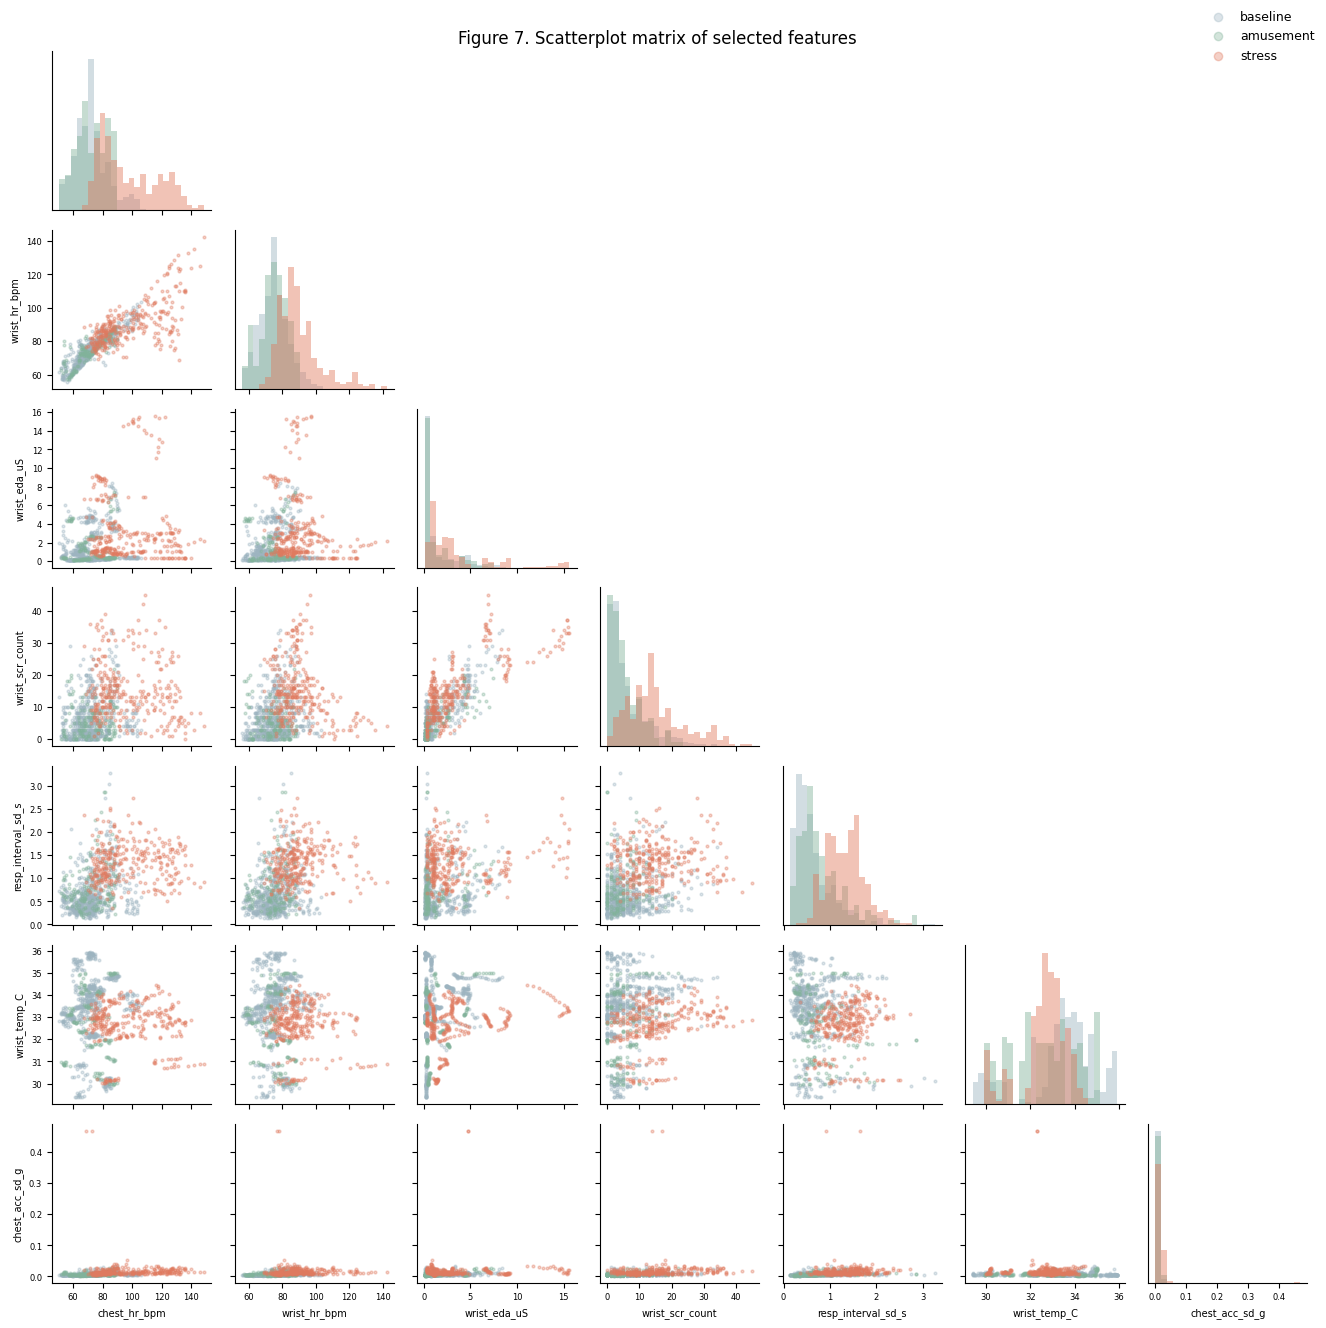

In [17]:
SCATTER_FEATURES = [f for f in ["chest_hr_bpm", "wrist_hr_bpm", "wrist_eda_uS", "wrist_scr_count",
                                "resp_interval_sd_s", "wrist_temp_C", "chest_acc_sd_g"] if f in FEATURES]
if "condition" in feats.columns and len(SCATTER_FEATURES) >= 2:
    fig = plots.scatter_matrix(feats, SCATTER_FEATURES, "Figure 7. Scatterplot matrix of selected features")
    plots.save_fig(fig, "fig7_scatter_matrix", cfg)
    plt.show()

**What Figure 7 shows.** Only two pairs show a clear linear relationship. Chest and wrist heart rate lie along a tight diagonal up to about 100 bpm, as expected for two sensors measuring the same heart; above that, stress windows fall *below* the line (the chest reads much higher than the wrist), suggesting erroneous noise from the chest sensor. Wrist EDA and SCR count rise together roughly linearly (more sweat-gland responses at higher skin conductance), so these two carry overlapping information. All the other relationship are non-linear, supporting use of Spearman Correlation later in the pipeline (Section 11.2). In subsequent modeling, one of each colinear feature will be dropped. 

## 9. Baseline normalization
People differ a lot in resting heart rate, skin conductance and skin temperature, and pooled across participants those differences can be larger than the stress effect. Each feature is therefore re-expressed relative to the participant's own resting level:

$$x_{bz} = \frac{x - \bar{x}_{\text{rest}}}{s_{\text{all}}}$$

where $\bar{x}_{\text{rest}}$ is the mean of that participant's baseline windows and $s_{\text{all}}$ is the SD of all of that participant's windows. 0 means "typical for this person at rest", and units are comparable across people. The SD uses all windows because baseline is very stable for some signals (wrist EDA in particular), and dividing by its tiny SD gave values in the hundreds; it needs no labels, so no stress information enters this step.

**Adapts to the data:** if the table has no `condition` column, or some participant has no baseline windows, all non-stress windows are used as the resting reference instead, and the cell says so.

This mirrors how a wearable would calibrate on a short resting recording. One caveat for modelling: under leave-one-participant-out evaluation, the held-out person's own resting windows are used to normalize their test windows, which assumes a new user would provide such a recording.

**Figure 8:** each line is one participant, from mean non-stress value (left) to mean stress value (right), before and after normalization.

Resting reference: baseline windows
Saved normalized table to data/processed/wesad_windows_normalized.csv


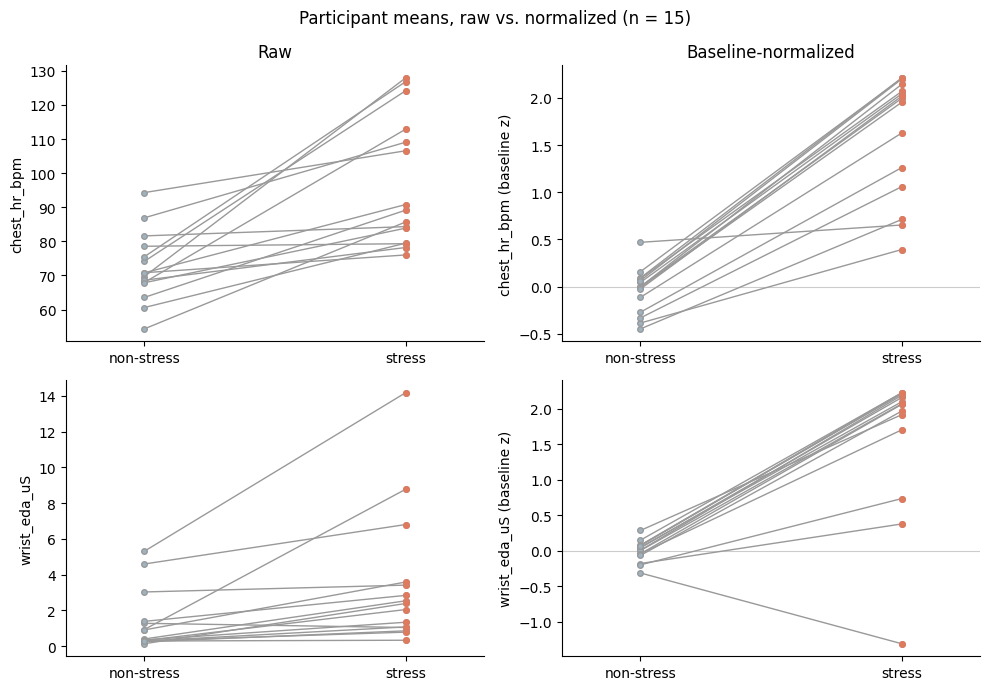

In [18]:
feats, reference = analysis.baseline_normalize(feats, FEATURES)
FEATURES_BZ = [f"{f}_bz" for f in FEATURES]
print(f"Resting reference: {reference}")
if DATA_SOURCE != "Upload my own feature table":
    feats.to_csv(cfg.processed_dir / "wesad_windows_normalized.csv", index=False)
    print(f"Saved normalized table to {cfg.processed_dir / 'wesad_windows_normalized.csv'}")

# show two familiar features if present, otherwise the first two features in the table
pair = [f for f in ("chest_hr_bpm", "wrist_eda_uS") if f in FEATURES] or FEATURES[:2]
fig, axes = plt.subplots(len(pair), 2, figsize=(10, 3.5 * len(pair)), squeeze=False)
for row, col in enumerate(pair):
    plots.slope_panel(axes[row, 0], feats, col, col)
    plots.slope_panel(axes[row, 1], feats, f"{col}_bz", f"{col} (baseline z)")
    axes[row, 1].axhline(0, color="#ccc", lw=0.8, zorder=0)
axes[0, 0].set_title("Raw")
axes[0, 1].set_title("Baseline-normalized")
fig.suptitle(f"Participant means, raw vs. normalized (n = {feats['subject'].nunique()})")
fig.tight_layout()
plots.save_fig(fig, "fig8_cohort_baseline_normalization", cfg)
plt.show()

**What Figure 8 shows.** In the raw values (left), participants' resting levels differ widely: resting chest heart rate ranges from about 55 to 95 bpm and resting wrist EDA from about 0.2 to 5 µS, and the lines cross each other. Some participants show very large rises under stress (chest heart rate up to about 128 bpm) and others small ones. After baseline normalization (right), every participant starts near 0 and nearly every line rises: the stress response becomes consistent and comparable across people. The one clear exception is wrist EDA for one participant (S17), whose skin conductance *fell* under stress; Figure 10 shows the same participant. The normalized stress values bunch near 2 because the SD in the denominator includes the stress windows themselves: when about 30% of a person's windows are stress windows and the two conditions are completely separated, the largest possible standardized gap is $1/\sqrt{0.3 \times 0.7} \approx 2.2$. The normalized values therefore show the direction and consistency of each person's response, not its absolute size.

## 10. Effect sizes: how large are the differences?
For each feature, **Cohen's d** measures the difference between stress and non-stress windows in standard-deviation units:

$$d = \frac{\bar{x}_{\text{stress}} - \bar{x}_{\text{non-stress}}}{s_{\text{pooled}}}, \qquad s_{\text{pooled}} = \sqrt{\frac{(n_1 - 1)s_1^2 + (n_0 - 1)s_0^2}{n_1 + n_0 - 2}}$$

(|d| ≈ 0.2 small, 0.5 medium, 0.8 large). It is computed three ways:

- **within-participant d**: one per participant, summarized by the median and by how many participants show the same direction;
- **pooled raw d**: all windows together, raw values;
- **pooled normalized d**: all windows together, baseline-normalized values.

These are **descriptive** effect sizes, not hypothesis tests. Windows from the same person overlap and are not independent, so no p-values are computed at the window level; significance is tested at the participant level in the next section. Within-participant d is inflated because each person's windows within one condition vary little, so pooled normalized d is the better guide to how well a feature will separate people a model has not seen.

In [19]:
d_by_subject, effects = analysis.effect_sizes(feats, FEATURES)
display(effects.round({"median within-participant d": 2, "pooled raw d": 2, "pooled normalized d": 2}))

,median within-participant d,same direction (n/N),pooled raw d,pooled normalized d
feature,,,,
wrist_eda_uS,6.930,14/15,0.850,2.160
chest_hr_bpm,4.840,15/15,1.770,2.420
chest_eda_uS,4.780,14/15,0.580,2.140
wrist_scr_count,2.210,15/15,1.280,2.090
resp_interval_sd_s,2.000,15/15,1.520,1.740
chest_acc_sd_g,1.860,15/15,0.550,1.650
wrist_hr_bpm,1.840,15/15,1.530,1.820
wrist_acc_sd_g,1.570,13/15,1.080,0.970
chest_temp_C,1.450,13/13,0.560,1.410


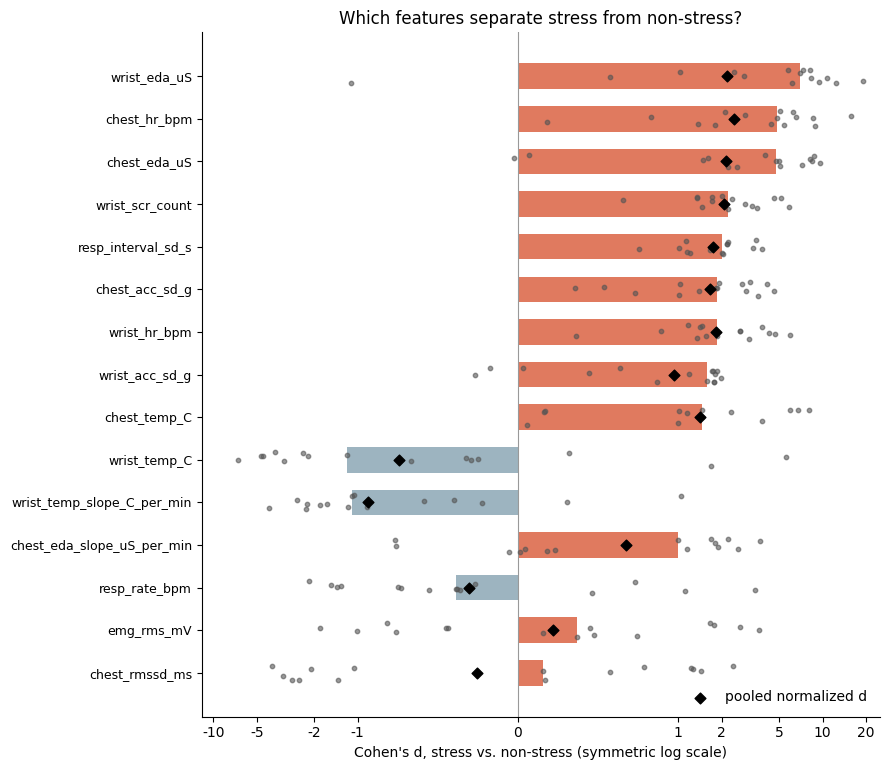

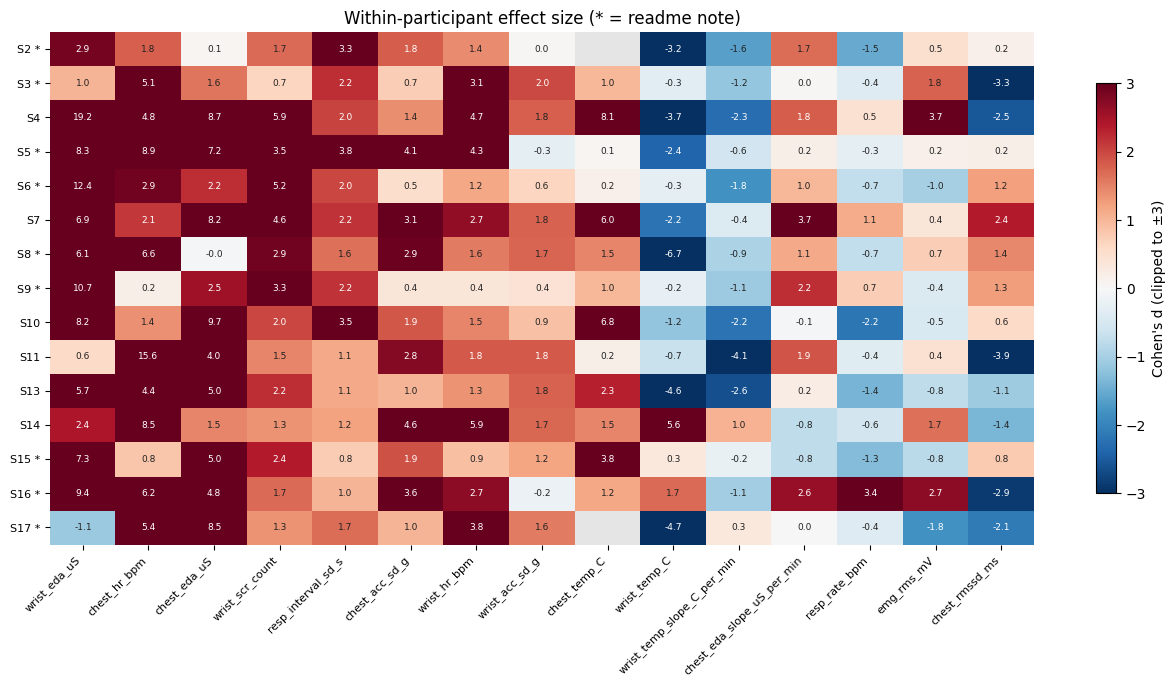

In [20]:
fig = plots.effect_size_chart(d_by_subject, effects)
plots.save_fig(fig, "fig9_cohort_effect_sizes", cfg)
plt.show()

starred = set(README_NOTES) | set(EXCLUDE_FEATURES) if IS_WESAD_TABLE else set()
fig, ax = plots.effect_heatmap(d_by_subject, starred)
ax.set_title("Within-participant effect size" + (" (* = readme note)" if starred else ""))
plots.save_fig(fig, "fig10_cohort_effect_heatmap", cfg)
plt.show()

**Figure 9:** grey dots are participants, bars the median within-participant d, black diamonds the pooled normalized d; bars to the right mean the feature rises under stress. **Figure 10:** the same d for each participant; a column of one colour means the feature moves the same way for everyone (* = readme note, see section 7; grey = not available).

**What Figures 9–10 show.** The features that rise most under stress are EDA (wrist and chest), chest heart rate, SCR count, breathing irregularity, movement and wrist heart rate, each in the same direction for 13–15 of 15 participants. Wrist temperature and its slope fall (the hands cool). Breathing rate, EMG and chest RMSSD have small median effects that point in different directions for different people. The black diamonds show what normalization buys: pooled across people, wrist EDA separates stress with d = 0.85 on raw values but d = 2.16 after normalization, and chest EDA goes from 0.58 to 2.14, because removing each person's resting level removes the between-person spread. In Figure 10 the heart-rate, chest-EDA, SCR and breathing-irregularity columns are red for every participant, while the exceptions are informative: S17 is the only participant whose wrist EDA fell (d = −1.1), S2's chest EDA barely changed (the settling-in decline in Figure 1), and S14 and S16 are the only participants whose wrist temperature rose. Within-participant d values are very large (up to 19) because each person's windows within one condition vary little; they show direction and consistency, while the pooled normalized d is the better guide to how well a feature will separate new people.

## 11. Inferential tests

Three analyses, each matched to the structure of the data (repeated windows within 15 participants):

1. **Participant-level paired tests (11.1):** does each feature change under stress? One stress-minus-non-stress difference per participant, so the 15 participants are the independent units.
2. **Collinearity (11.2):** which features carry overlapping information? This decides which features can enter a regression together.
3. **Conditional (fixed-effects) logistic regression (11.3):** which features *independently* predict a stress window when each participant is compared only with themselves.

### 11.1 Participant-level paired tests

For each feature and participant $i$, take the difference between their mean during stress and their mean during non-stress, $D_i = \bar{x}_{i,\text{stress}} - \bar{x}_{i,\text{non-stress}}$ (on the log scale for EDA, so $D_i$ is a log ratio).

**Wilcoxon signed-rank test.** Rank the absolute differences $|D_i|$ from smallest (rank 1) to largest (rank $n$), then add up the ranks of the participants whose feature went up:

$$W^{+} = \sum_{i:\,D_i > 0} R_i, \qquad R_i = \text{rank of } |D_i|$$

If stress had no effect, each difference would be equally likely to be positive or negative, so $W^{+}$ would sit near its middle value $n(n+1)/4$; a $W^{+}$ near 0 or near its maximum $n(n+1)/2$ is evidence of a consistent shift. The test assumes the differences are roughly symmetric around their centre.

**Sign test.** Count how many participants went up, $S = \#\{i : D_i > 0\}$. With no effect, $S \sim \text{Binomial}(n, 0.5)$, like flipping a coin for each person. It ignores how large each change is, so it needs no symmetry assumption; it is used here as the robustness check.

**Multiple-testing corrections.** Fifteen features are tested, so the $m = 15$ p-values are adjusted. With the p-values sorted from smallest, $p_{(1)} \le \dots \le p_{(m)}$:

$$\text{Holm: } \tilde p_{(k)} = \max_{j \le k} \min\big(1,\,(m - j + 1)\,p_{(j)}\big) \qquad\qquad \text{Benjamini–Hochberg: } \tilde p_{(k)} = \min_{j \ge k} \min\Big(1,\,\frac{m}{j}\,p_{(j)}\Big)$$

Holm controls the chance of *any* false positive among the 15 tests; Benjamini–Hochberg controls the expected *share* of false positives among the features called significant, so it is less strict.

,n,went up (n/N),mean diff,median diff,skewness,Wilcoxon p,sign test p,Wilcoxon p (BH),Wilcoxon p (Holm),sign test p (BH),sign test p (Holm)
feature,,,,,,,,,,,
chest_hr_bpm,15,15/15,24.604,20.013,0.510,6.1e-05,6.1e-05,1.8e-04,9.2e-04,1.8e-04,9.2e-04
wrist_hr_bpm,15,15/15,15.058,9.836,0.540,6.1e-05,6.1e-05,1.8e-04,9.2e-04,1.8e-04,9.2e-04
wrist_scr_count,15,15/15,9.131,8.036,0.650,6.1e-05,6.1e-05,1.8e-04,9.2e-04,1.8e-04,9.2e-04
resp_interval_sd_s,15,15/15,0.662,0.615,0.710,6.1e-05,6.1e-05,1.8e-04,9.2e-04,1.8e-04,9.2e-04
chest_acc_sd_g,15,15/15,0.011,0.008,2.730,6.1e-05,6.1e-05,1.8e-04,9.2e-04,1.8e-04,9.2e-04
chest_eda_uS (log),15,14/15,0.467,0.452,0.520,1.2e-04,9.8e-04,3.1e-04,1.2e-03,1.8e-03,8.8e-03
chest_temp_C,13,13/13,0.455,0.409,0.370,2.4e-04,2.4e-04,5.2e-04,2.2e-03,6.1e-04,2.4e-03
wrist_eda_uS (log),15,14/15,1.139,1.234,0.240,3.1e-04,9.8e-04,5.7e-04,2.4e-03,1.8e-03,8.8e-03
wrist_temp_slope_C_per_min,15,2/15,-0.093,-0.118,0.670,6.1e-04,7.4e-03,9.2e-04,4.3e-03,1.1e-02,5.2e-02


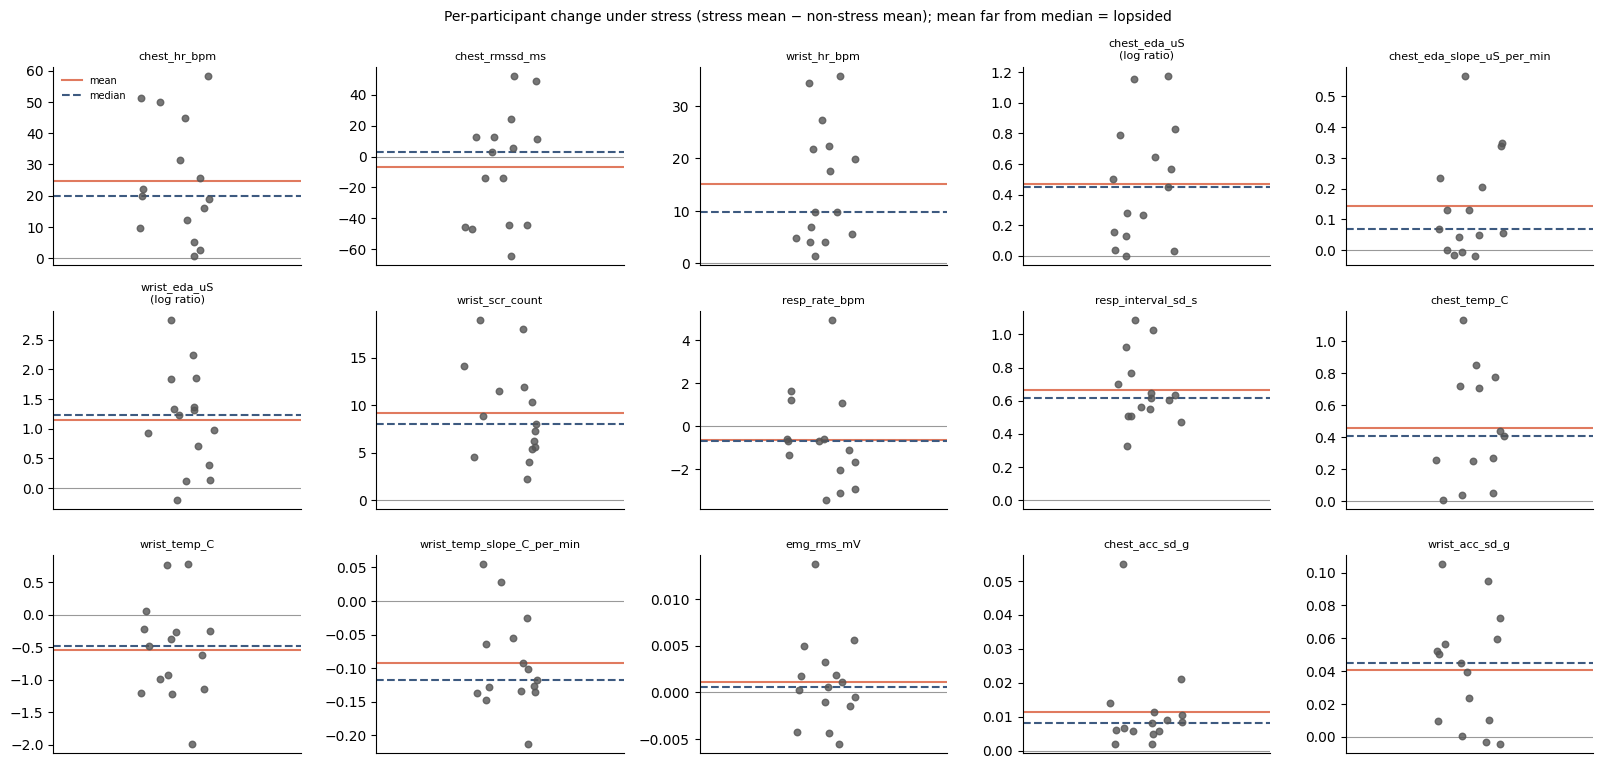

In [21]:
# ---- Participant-level paired tests: is each feature different under stress? ----
# One pair of values per participant (mean of their stress windows vs mean of their non-stress windows),
# so the 15 participants, not the ~1,000 overlapping windows, are the independent observations.

LOG_FEATURES = ["chest_eda_uS", "wrist_eda_uS"]   # skewed, always-positive features: compare on the log scale


def paired_differences(df, features, log_features=()):
    """Participants x features table of (mean under stress - mean under non-stress)."""
    means = df.groupby(["subject", "stress"])[features].mean()   # one row per participant per condition
    stress = means.xs(1, level="stress").copy()                    # .copy() so the log step edits our own table
    rest = means.xs(0, level="stress").copy()
    for f in log_features:
        if f in features:
            if (stress[f] <= 0).any() or (rest[f] <= 0).any():
                raise ValueError(f"{f} has values <= 0; it cannot be log-transformed")
            stress[f], rest[f] = np.log(stress[f]), np.log(rest[f])   # difference of logs = log of the ratio
    return stress - rest


def holm(p):
    """Holm-adjusted p-values (controls the chance of any false positive)."""
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order])
    out = np.empty_like(p)
    out[order] = np.minimum(adj, 1)
    return out


def benjamini_hochberg(p):
    """Benjamini-Hochberg-adjusted p-values (controls the expected share of false positives)."""
    p = np.asarray(p, float)
    order = np.argsort(p)[::-1]                       # largest p first
    ranks = len(p) - np.arange(len(p))                # rank of each p in ascending order
    adj = np.minimum.accumulate(p[order] * len(p) / ranks)
    out = np.empty_like(p)
    out[order] = np.minimum(adj, 1)
    return out


diffs = paired_differences(feats, FEATURES, LOG_FEATURES)

rows = []
for f in FEATURES:
    d = diffs[f].dropna()                             # e.g. chest temperature is missing for S2 and S17
    d = d[d != 0]                                     # zero differences carry no direction
    if len(d) < 6:                                    # too few participants for a meaningful test
        rows.append({"feature": f, "n": len(d)})
        continue
    n_up = int((d > 0).sum())
    rows.append({
        "feature": f + (" (log)" if f in LOG_FEATURES else ""),
        "n": len(d),
        "went up (n/N)": f"{n_up}/{len(d)}",
        "mean diff": d.mean(),
        "median diff": d.median(),
        "skewness": scipy.stats.skew(d),                    # ~0 = symmetric; |skew| > 1 = clearly lopsided
        "Wilcoxon p": scipy.stats.wilcoxon(d).pvalue,       # signed-rank: uses direction and ranked size
        "sign test p": scipy.stats.binomtest(n_up, len(d), 0.5).pvalue,   # direction only; no symmetry assumption
    })
paired = pd.DataFrame(rows).set_index("feature")

tested = paired["Wilcoxon p"].notna()
for col in ("Wilcoxon p", "sign test p"):
    paired.loc[tested, f"{col} (BH)"] = benjamini_hochberg(paired.loc[tested, col])
    paired.loc[tested, f"{col} (Holm)"] = holm(paired.loc[tested, col])
paired = paired.sort_values("Wilcoxon p")
shown = paired.round({"mean diff": 3, "median diff": 3, "skewness": 2})
for c in [c for c in shown.columns if " p" in c]:                  # every p-value column
    shown[c] = shown[c].map(lambda v: f"{v:.1e}" if pd.notna(v) else "")
display(shown)
# ---- Plot: one dot per participant, per feature ---------------------------------
ncols = 5
nrows = int(np.ceil(len(FEATURES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.6 * nrows), squeeze=False)
rng = np.random.default_rng(0)
for ax, f in zip(axes.ravel(), FEATURES):
    d = diffs[f].dropna()
    ax.scatter(rng.uniform(-0.15, 0.15, len(d)), d, s=22, color="#555", alpha=0.8, zorder=3)
    ax.axhline(0, color="#999", lw=0.8)                                       # no change
    ax.axhline(d.mean(), color="#e07a5f", lw=1.5, label="mean")
    ax.axhline(d.median(), color="#3d5a80", lw=1.5, ls="--", label="median")
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([])
    ax.set_title(f + ("\n(log ratio)" if f in LOG_FEATURES else ""), fontsize=8)
for ax in axes.ravel()[len(FEATURES):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=7, loc="upper left")
fig.suptitle("Per-participant change under stress (stress mean − non-stress mean); "
             "mean far from median = lopsided", fontsize=10)
fig.tight_layout()
plots.save_fig(fig, "fig11_paired_differences", cfg)
plt.show()

**Figure 11.** This feature checks the symmetry assumption for the Wilcoxon signed-rank test. If the mean is near the median, than the symmetry assumption is met. This is the case for most of the features ecept for wrist_hr_bpm. It is worth noting that each graph in the figure is scaled indenpendently. Comparing each participant’s mean feature value during stress with their mean during non-stress (n = 15 paired participants), heart rate (chest and wrist), skin conductance responses, breathing irregularity and chest movement increased in all 15 participants (Wilcoxon signed-rank and sign test p ≈ 6 × 10⁻⁵), and log-transformed chest and wrist electrodermal activity (EDA) increased in 14 of 15. Several features had skewed or bimodal distributions around the median, which violates the symmetry assumption of the signed-rank test, so effects were considered robust only when the distribution-free sign test agreed. 

### 11.2 Collinearity between features

### Spearman's Rank Correlation Coefficient

**Spearman's rank correlation coefficient (ρ, "rho")** measures the strength and direction
of the **monotonic** relationship between two variables. Rather than using raw values, it
works by ranking the data and computing correlation on those ranks. It ranges from **-1 to +1**,
where:

- **ρ = +1** — Perfect positive monotonic relationship (as X increases, Y consistently increases)
- **ρ = 0** — No monotonic relationship
- **ρ = -1** — Perfect negative monotonic relationship (as X increases, Y consistently decreases)

### Formula

$$\rho = 1 - \frac{6\sum_{i=1}^{n} d_i^2}{n(n^2 - 1)}$$

Where $d_i$ is the difference between the ranks of each paired observation, and $n$ is the
number of observations.

### Interpreting ρ

| Absolute Value of ρ | Interpretation |
|---|---|
| 0.00 – 0.19 | Negligible or no correlation |
| 0.20 – 0.39 | Weak correlation |
| 0.40 – 0.59 | Moderate correlation |
| 0.60 – 0.79 | Strong correlation |
| 0.80 – 1.00 | Very strong correlation |

### Key Assumptions

1. Variables can be **continuous or ordinal**
2. The relationship between variables is **monotonic** (consistently increasing or decreasing,
   but not necessarily linear)
3. Observations are **independent** of one another

### Pearson's vs. Spearman's — When to Use Each

| Condition | Use |
|---|---|
| Continuous data, linear relationship, no outliers | Pearson's (r) |
| Ordinal data or non-normal distributions | Spearman's (ρ) |
| Outliers present | Spearman's (ρ) |
| Monotonic but non-linear relationship | Spearman's (ρ) |
| Ranked data | Spearman's (ρ) |

### Important Notes

- Spearman's ρ is a **non-parametric** alternative to Pearson's r — it makes no assumption
  about the distribution of the data.
- A **monotonic relationship** means the variables tend to move in the same direction, but
  not necessarily at a constant rate — unlike the strictly linear requirement of Pearson's.
- Spearman's is more **robust to outliers** because it operates on ranks rather than raw values.
- When data are normally distributed with a linear relationship and no outliers, Pearson's r
  is generally preferred as it is more statistically powerful.

### Variance Inflation Factor (VIF)

The **variance inflation factor** measures how much of a feature's information is already contained in the *other* features. For feature $j$, imagine predicting it from all the remaining features with a linear regression:

$$x_j = \alpha_0 + \sum_{k \neq j} \alpha_k x_k + \varepsilon$$

Let $R_j^2$ be the proportion of the variance in $x_j$ explained by that regression. Then:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

**Why "variance inflation."** In a regression model that includes feature $j$, the variance of its estimated coefficient is

$$\operatorname{Var}(\hat\beta_j) = \frac{\sigma^2}{(n-1)\,\operatorname{Var}(x_j)} \cdot \text{VIF}_j$$

so VIF is exactly the factor by which overlap with the other features inflates that variance. The standard error grows by $\sqrt{\text{VIF}_j}$: a VIF of 4 doubles the standard error, widening confidence intervals and making the coefficient unstable.

**Computing it.** With $\mathbf{R}$ the correlation matrix of the features, the VIFs are the diagonal of its inverse, which gives every feature's VIF at once without fitting a separate regression for each:

$$\text{VIF}_j = \left(\mathbf{R}^{-1}\right)_{jj}$$

**Interpreting VIF**

| VIF | $R_j^2$ | Interpretation |
|---|---|---|
| 1 | 0 | No overlap: the feature carries entirely unique information |
| 1 – 5 | 0 – 0.80 | Low to moderate overlap; usually acceptable |
| 5 – 10 | 0.80 – 0.90 | Substantial overlap; coefficients become unstable |
| > 10 | > 0.90 | Serious collinearity; remove or combine features |

**Why VIF complements the correlation heatmap.** Pairwise correlations only show overlap between *two* features at a time. VIF captures overlap with a *combination* of features: a feature can correlate only moderately with each of several others yet be almost fully predictable from them together.

**When it matters.** Collinearity is a problem mainly for models whose **coefficients are interpreted**, such as the conditional logistic regression in section 11.3, where each odds ratio is read as an effect "holding the other features constant." It matters much less for prediction-focused models such as the decision tree and SVM in section 12, which predict well with correlated features but split importance between them.

Feature pairs with |rho| >= 0.7:


,feature A,feature B,spearman rho
69,chest_hr_bpm,wrist_hr_bpm,0.890
104,wrist_eda_uS,wrist_scr_count,0.800


VIF computed on 1,015 complete windows (chest_temp_C left out for missing values):


,VIF
chest_hr_bpm,5.300
wrist_scr_count,4.800
wrist_hr_bpm,4.000
wrist_eda_uS,3.500
resp_interval_sd_s,2.100
wrist_acc_sd_g,2.000
chest_eda_uS,1.900
chest_rmssd_ms,1.700
resp_rate_bpm,1.600
emg_rms_mV,1.400


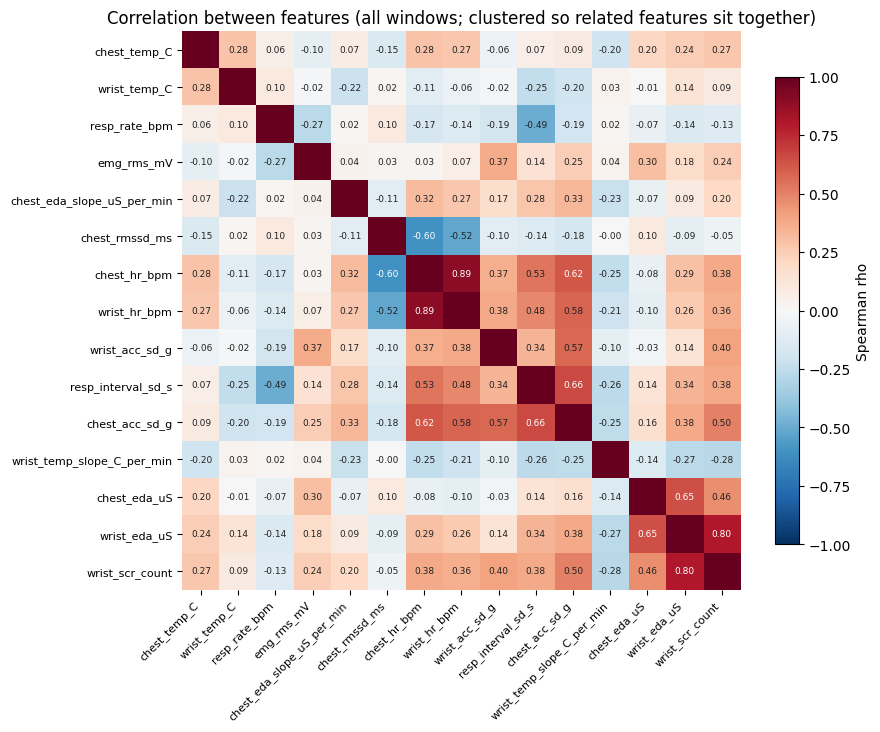

In [22]:
# ---- Which features carry overlapping information? ---------------------------
# Spearman correlation (rank-based, robust to skew and outliers) between every pair of features,
# plus the variance inflation factor (VIF) for each feature.


HIGH_CORR = 0.7          # |rho| above this = strongly overlapping pair
cols = FEATURES          # use FEATURES_BZ instead to check the baseline-normalized versions

corr = feats[cols].corr(method="spearman")               # pairwise, ignores missing values

# Order features so correlated ones sit next to each other (hierarchical clustering on 1 - |rho|)
dist = squareform(1 - corr.abs().to_numpy(), checks=False)
order = corr.columns[leaves_list(linkage(dist, method="average"))]
corr = corr.loc[order, order]

# Strongly correlated pairs
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # each pair once
pairs = (upper.stack().rename("spearman rho").reset_index()
              .rename(columns={"level_0": "feature A", "level_1": "feature B"}))
pairs = pairs[pairs["spearman rho"].abs() >= HIGH_CORR].sort_values("spearman rho", key=abs, ascending=False)
print(f"Feature pairs with |rho| >= {HIGH_CORR}:")
display(pairs.round(2) if len(pairs) else "none")

# VIF = how much a feature's coefficient variance is inflated by the other features.
# It equals the diagonal of the inverse correlation matrix (complete rows only).
# Rule of thumb: VIF > 5 is worth attention, VIF > 10 is serious collinearity.
complete = feats[cols].dropna(axis=1, thresh=int(0.9 * len(feats))).dropna()   # drop mostly-missing columns, then rows
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(complete.to_numpy(), rowvar=False))),
                index=complete.columns, name="VIF").sort_values(ascending=False)
print(f"VIF computed on {len(complete):,} complete windows "
      f"({', '.join(sorted(set(cols) - set(complete.columns))) or 'no columns'} left out for missing values):")
display(vif.round(1).to_frame())

# Heatmap
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
for (i, j), v in np.ndenumerate(corr.to_numpy()):
    if i != j:
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(v) > 0.6 else "#222")
ax.set_xticks(range(len(order)), order, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(order)), order, fontsize=8)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman rho")
ax.set_title("Correlation between features (all windows; clustered so related features sit together)")
fig.tight_layout()
plots.save_fig(fig, "fig12_feature_correlation", cfg)
plt.show()

**What Figure 12 and the tables show.** Two feature pairs are strongly correlated: chest and wrist heart rate (ρ = 0.89) and wrist EDA and SCR count (ρ = 0.80). A moderate cluster (ρ ≈ 0.5–0.66) links chest movement, wrist movement, breathing irregularity and heart rate: during the stress task participants stand, talk and gesture, which raises all of them together. Chest and wrist EDA correlate at 0.65, and chest RMSSD is negatively correlated with heart rate (ρ ≈ −0.6 with chest heart rate), as expected physiologically because heart rate variability falls when heart rate rises. Temperature, temperature slope, EDA slope and EMG are largely independent of everything else. All VIFs are below 5 except chest heart rate (5.3), so collinearity across the full set is moderate. For the regression, which must interpret each feature while holding the others constant, only one feature from each strongly correlated pair is used (section 11.3). Correlations here are across all windows, so they partly reflect differences between people rather than within-person co-variation.

### 11.3 Conditional (fixed-effects) logistic regression

The paired tests look at one feature at a time. This model asks which features predict a stress window **when considered together**, so each odds ratio is adjusted for the others. A conditional logistic regression is a logistic regression for clustered binary outcomes (stress / non-stress) in which every cluster, here every participant, gets its own intercept, so each person is compared only with themselves:

$$\log\frac{P(\text{stress}_{ij} = 1)}{1 - P(\text{stress}_{ij} = 1)} = \alpha_i + \beta_1\,\text{HR}_{ij} + \beta_2\,\text{EDA}_{ij} + \beta_3\,\text{RespVar}_{ij} + \beta_4\,\text{Temp}_{ij}$$

for window $j$ of participant $i$, with every predictor baseline-normalized (section 9).

**Fixed effects.** $\alpha_i$ is a participant-specific intercept. It absorbs everything that is constant within a person (resting physiology, fitness, how the sensors sat, how long their stress task lasted), so the $\beta$'s are estimated only from comparisons *within* each person. Instead of estimating 15 separate intercepts, the conditional likelihood asks: given that participant $i$ had $k_i$ stress windows, how likely is it that it was *these* windows and not any other $k_i$ of their $n_i$ windows?

$$L_i(\beta) = \frac{\exp\big(\sum_{j:\,y_{ij}=1} x_{ij}^\top\beta\big)}{\sum_{S \subseteq \{1,\dots,n_i\},\ |S| = k_i} \exp\big(\sum_{j \in S} x_{ij}^\top\beta\big)}$$

$\alpha_i$ cancels out of this ratio, so it never has to be estimated. $e^{\beta_k}$ is a within-person **odds ratio**: how much the odds that a window is a stress window multiply for each 1-SD rise in that feature above the person's resting level, holding the other features constant. Participants with only one class contribute nothing to $L_i$; every participant here has both stress and non-stress windows.

**Why this model.** It is the simplest model that respects that windows are nested within people, and it needs fewer assumptions than the alternatives: GEE estimates population-averaged effects but its robust standard errors are unreliable with only 15 participants, and a mixed-effects model assumes the $\alpha_i$ are normally distributed and unrelated to the predictors. The fixed-effects model makes neither assumption.

**Limitation.** Conditioning removes the differences *between* people, but the standard errors still treat the windows *within* a person as independent once $\alpha_i$ is accounted for. They are not: the 60-second windows overlap by 50%, and physiology changes slowly, so neighbouring windows carry partly the same information. **The p-values and confidence intervals from the main fit are therefore too small.** Step 3 refits the model on non-overlapping windows only as a sensitivity check. That removes the overlap but not the slower autocorrelation between consecutive minutes, so even those p-values are approximate. The direction and size of the odds ratios are more trustworthy than the exact p-values.

**Predictors.** One per body system, chosen with the collinearity analysis (11.2): wrist heart rate (not chest HR: the two overlap, ρ = 0.89, and chest HR may include ECG detection artifact during speech), wrist EDA level (not SCR count: ρ = 0.80), breathing irregularity, and wrist temperature. Movement is left out on purpose: it rises because the stress task makes people stand and talk, not because of stress physiology.

**Assumptions checked below:** (1) no strongly skewed predictors (Yeo–Johnson check), (2) low collinearity (VIF), (3) a linear relationship between each predictor and the log-odds, and (4) results that hold up on non-overlapping windows. Normality and equal variances are **not** assumptions of logistic regression.

#### Step 1: Do any features need a Yeo–Johnson transformation?
A strongly skewed predictor can give a few extreme windows too much influence on a regression and can make its relationship with the log-odds curved. The **Yeo–Johnson** transformation reshapes a variable towards symmetry; unlike the log or Box–Cox transforms it also works for zero and negative values, which baseline-normalized features have. Decision rule: transform a feature if its |skewness| > 1. The table checks all 15 features, raw and baseline-normalized, and shows the skewness after transforming.

In [23]:
SKEW_THRESHOLD = 1.0      # |skewness| above this -> apply Yeo-Johnson before linear models

def skew_after_yeo_johnson(series):
    """Skewness after a Yeo-Johnson transform fitted to this column (missing values are ignored)."""
    values = series.dropna().to_numpy().reshape(-1, 1)
    return stats.skew(PowerTransformer(method="yeo-johnson").fit_transform(values).ravel())

skew_check = pd.DataFrame({
    "skew (raw)": feats[FEATURES].skew().to_numpy(),
    "skew (baseline-normalized)": feats[FEATURES_BZ].skew().to_numpy(),
}, index=FEATURES)
skew_check["needs Yeo-Johnson?"] = skew_check["skew (baseline-normalized)"].abs() > SKEW_THRESHOLD
skew_check["skew after Yeo-Johnson"] = [skew_after_yeo_johnson(feats[f"{f}_bz"]) for f in FEATURES]
display(skew_check.round(2))

YJ_FEATURES = [f"{f}_bz" for f in skew_check.index[skew_check["needs Yeo-Johnson?"]]]
print(f"Baseline-normalized features needing Yeo-Johnson (|skew| > {SKEW_THRESHOLD}): {YJ_FEATURES or 'none'}")

,skew (raw),skew (baseline-normalized),needs Yeo-Johnson?,skew after Yeo-Johnson
chest_hr_bpm,1.220,0.580,False,-0.150
chest_rmssd_ms,1.250,0.710,False,-0.020
wrist_hr_bpm,1.180,0.530,False,-0.080
chest_eda_uS,1.540,0.590,False,-0.130
chest_eda_slope_uS_per_min,4.380,0.780,False,-0.070
wrist_eda_uS,2.570,0.620,False,-0.090
wrist_scr_count,1.320,0.810,False,0.010
resp_rate_bpm,0.390,0.050,False,0.010
resp_interval_sd_s,0.910,0.850,False,-0.020
chest_temp_C,-1.400,0.150,False,-0.060


Baseline-normalized features needing Yeo-Johnson (|skew| > 1.0): ['chest_acc_sd_g_bz', 'wrist_acc_sd_g_bz']


**Result of the Yeo–Johnson check.** On the raw scale, 12 of the 15 features are strongly skewed (|skewness| > 1). After baseline normalization only the two movement features remain above the threshold (chest movement 1.5, wrist movement 1.3): most of the raw skew came from a few participants with high resting levels, and normalization removes those between-person differences. Yeo–Johnson brings every feature to |skewness| < 0.2. **Decision:** none of the four regression predictors needs transforming (skewness 0.53 for wrist heart rate, 0.62 for wrist EDA, 0.85 for breathing irregularity and −0.25 for wrist temperature), so they enter the regression untransformed and their odds ratios stay in easy-to-read units (per 1 SD above resting level). Because the movement features do exceed the threshold, the linear models in section 12 include a Yeo–Johnson step inside their pipeline, fitted separately in each cross-validation fold.

#### Step 2: Build the model data, check collinearity and linearity
**Figure 13** checks linearity in the log-odds. Each predictor is split into 10 equal-sized bins; each dot is the log-odds of stress among the windows in one bin, plotted at the bin's mean value. If the relationship is linear in the log-odds, as the model assumes, the dots fall roughly on a straight line (dashed). Because every predictor is already centred on each person's resting level, this pooled check is a reasonable stand-in for the within-person relationship the model uses.

Model data: 1,015 windows from 15 participants (0 windows dropped for missing values)
No regression predictor exceeds the skewness threshold, so none is transformed (odds ratios stay per 1 SD).


,VIF
wrist_hr_bpm_bz,1.380
wrist_eda_uS_bz,1.300
resp_interval_sd_s_bz,1.440
wrist_temp_C_bz,1.130


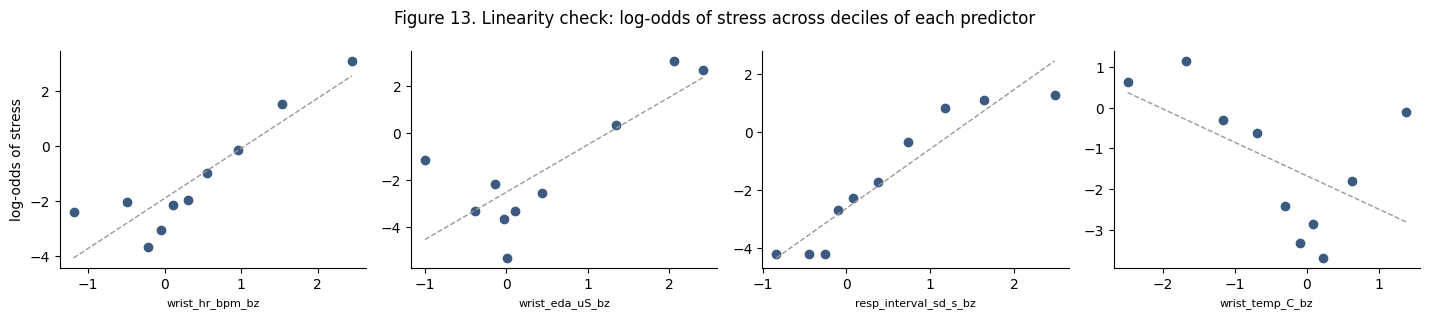

In [24]:
FE_PREDICTORS = ["wrist_hr_bpm_bz", "wrist_eda_uS_bz", "resp_interval_sd_s_bz", "wrist_temp_C_bz"]

absent = [p for p in FE_PREDICTORS if p not in feats.columns]
if absent:
    raise ValueError(f"Regression predictors not in this table: {absent}. Edit FE_PREDICTORS to match the features available.")

fe_df = feats[["subject", "t_start_min", "stress"] + FE_PREDICTORS].dropna().reset_index(drop=True)
print(f"Model data: {len(fe_df):,} windows from {fe_df['subject'].nunique()} participants "
      f"({len(feats) - len(fe_df)} windows dropped for missing values)")

# Conditional step: transform any predictor that failed the skewness check
to_transform = [p for p in FE_PREDICTORS if p in YJ_FEATURES]
if to_transform:
    fe_df[to_transform] = PowerTransformer(method="yeo-johnson").fit_transform(fe_df[to_transform])
    print(f"Yeo-Johnson applied to: {to_transform}")
else:
    print("No regression predictor exceeds the skewness threshold, so none is transformed (odds ratios stay per 1 SD).")

# Collinearity among the chosen predictors (VIF = diagonal of the inverse correlation matrix)
vif_fe = pd.Series(np.diag(np.linalg.inv(np.corrcoef(fe_df[FE_PREDICTORS].to_numpy(), rowvar=False))),
                   index=FE_PREDICTORS, name="VIF")
display(vif_fe.round(2).to_frame())


def binned_log_odds(ax, x, y, bins=10):
    """Log-odds of y within quantile bins of x (0.5 added to counts so empty classes stay finite)."""
    binned = pd.DataFrame({"x": x, "y": y}).assign(bin=pd.qcut(x, bins, duplicates="drop"))
    g = binned.groupby("bin", observed=True).agg(x=("x", "mean"), events=("y", "sum"), n=("y", "size"))
    log_odds = np.log((g["events"] + 0.5) / (g["n"] - g["events"] + 0.5))
    ax.plot(g["x"], log_odds, "o", color="#3d5a80")
    slope, intercept = np.polyfit(g["x"], log_odds, 1)
    xs = np.linspace(g["x"].min(), g["x"].max(), 50)
    ax.plot(xs, intercept + slope * xs, "--", color="#999", lw=1)


fig, axes = plt.subplots(1, len(FE_PREDICTORS), figsize=(3.6 * len(FE_PREDICTORS), 3.2), squeeze=False)
for ax, p in zip(axes[0], FE_PREDICTORS):
    binned_log_odds(ax, fe_df[p], fe_df["stress"])
    ax.set_xlabel(p, fontsize=8)
axes[0, 0].set_ylabel("log-odds of stress")
fig.suptitle("Figure 13. Linearity check: log-odds of stress across deciles of each predictor")
fig.tight_layout()
plots.save_fig(fig, "fig13_logit_linearity", cfg)
plt.show()


**What Figure 13 shows.** For wrist heart rate and breathing irregularity the decile points fall close to the straight line, so a linear relationship with the log-odds is a reasonable assumption (breathing irregularity flattens slightly in the top decile). Wrist EDA rises overall, but the lowest decile sits well above the line: some stress windows have EDA *below* the person's resting level (the pattern seen for S17), so the linear fit is approximate. Wrist temperature is clearly **not** linear: the log-odds of stress are highest at the coolest temperatures, lowest near the resting level, and rise again in the warmest decile. A single linear term understates this curved relationship, so the temperature odds ratio below should be read with caution; a quadratic or spline term would be the next refinement. VIFs are all below 1.5, so the four predictors are not collinear.

#### Step 3: Fit the model and refit on non-overlapping windows
The first table reports odds ratios with 95% confidence intervals, p-values and Holm-adjusted p-values across the four predictors, using all windows.

**Sensitivity check: non-overlapping windows.** Windows start every 30 s but last 60 s, so each window shares half its data with the next one. The model is refitted on a subset in which no two windows from the same person overlap (within each participant, a window is kept only if it starts at least 60 s after the last kept window). This roughly halves the data. If the main p-values were only small because overlapping windows were counted twice, the effects would lose significance here.

In [25]:
def fit_conditional_logit(df, predictors):
    """Conditional (fixed-effects) logistic regression: one intercept per participant, conditioned out of the likelihood.

    Participants with only stress or only non-stress windows carry no information and are left out.
    """
    usable = df.groupby("subject")["stress"].transform("nunique") == 2
    d = df[usable]
    return ConditionalLogit(d["stress"], d[predictors], groups=d["subject"]).fit(disp=0)


def odds_ratio_table(fit):
    """Odds ratios, 95% CIs, p-values and Holm-adjusted p-values (holm() is defined in section 11.1)."""
    ci = fit.conf_int()
    table = pd.DataFrame({"odds ratio": np.exp(fit.params), "95% CI low": np.exp(ci[0]),
                          "95% CI high": np.exp(ci[1]), "p": fit.pvalues})
    table["p (Holm)"] = holm(table["p"])
    return table


def show_or(table):
    """Round odds ratios; show p-values in scientific notation."""
    shown = table.round(2)
    for c in ("p", "p (Holm)"):
        shown[c] = table[c].map(lambda v: f"{v:.1e}")
    return shown


def non_overlapping(df, window_min):
    """Keep, within each participant, only windows starting at least one window length after the last kept one."""
    keep = []
    for _, g in df.sort_values(["subject", "t_start_min"]).groupby("subject"):
        last_start = -np.inf
        for idx, start in g["t_start_min"].items():
            if start >= last_start + window_min - 1e-9:
                keep.append(idx)
                last_start = start
    return df.loc[sorted(keep)]


fe_fit = fit_conditional_logit(fe_df, FE_PREDICTORS)
fe_table = odds_ratio_table(fe_fit)
print(f"Main model: all {len(fe_df):,} windows")
display(show_or(fe_table))


# Sensitivity: refit on non-overlapping windows only
fe_df_nonoverlap = non_overlapping(fe_df, cfg.window_s / 60)
nonoverlap_fit = fit_conditional_logit(fe_df_nonoverlap, FE_PREDICTORS)
nonoverlap_table = odds_ratio_table(nonoverlap_fit)
print(f"\nSensitivity model: {len(fe_df_nonoverlap):,} non-overlapping windows")
display(show_or(nonoverlap_table))

comparison = pd.DataFrame({
    "OR (all windows)": fe_table["odds ratio"],
    "OR (non-overlapping)": nonoverlap_table["odds ratio"],
    "SE ratio (non-overlap / all)": nonoverlap_fit.bse / fe_fit.bse,
    "p Holm (all windows)": fe_table["p (Holm)"].map(lambda v: f"{v:.1e}"),
    "p Holm (non-overlapping)": nonoverlap_table["p (Holm)"].map(lambda v: f"{v:.1e}"),
})
print("Main fit vs. non-overlapping refit:")
display(comparison.round(2))


Main model: all 1,015 windows


,odds ratio,95% CI low,95% CI high,p,p (Holm)
wrist_hr_bpm_bz,15.020,7.970,28.280,4.9e-17,1.5e-16
wrist_eda_uS_bz,14.030,8.270,23.820,1.3e-22,5.4e-22
resp_interval_sd_s_bz,4.520,2.960,6.890,2.9e-12,5.9e-12
wrist_temp_C_bz,0.380,0.260,0.570,2.7e-06,2.7e-06



Sensitivity model: 519 non-overlapping windows


,odds ratio,95% CI low,95% CI high,p,p (Holm)
wrist_hr_bpm_bz,15.900,6.420,39.400,2.3e-09,7.0e-09
wrist_eda_uS_bz,10.720,5.360,21.430,2.0e-11,7.9e-11
resp_interval_sd_s_bz,4.980,2.620,9.480,1.0e-06,2.0e-06
wrist_temp_C_bz,0.470,0.280,0.800,5.2e-03,5.2e-03


Main fit vs. non-overlapping refit:


,OR (all windows),OR (non-overlapping),SE ratio (non-overlap / all),p Holm (all windows),p Holm (non-overlapping)
wrist_hr_bpm_bz,15.020,15.900,1.430,1.5e-16,7.0e-09
wrist_eda_uS_bz,14.030,10.720,1.310,5.4e-22,7.9e-11
resp_interval_sd_s_bz,4.520,4.980,1.520,5.9e-12,2.0e-06
wrist_temp_C_bz,0.380,0.470,1.320,2.7e-06,5.2e-03


**What the conditional logistic regression shows.** Comparing each participant only with themselves and holding the other predictors constant, each 1-SD rise above a person's resting level multiplies the odds that a window is a stress window by **15.0** for wrist heart rate (95% CI 8.0–28.3), **14.0** for wrist EDA (8.3–23.8) and **4.5** for breathing irregularity (3.0–6.9). Each 1-SD rise in wrist temperature multiplies them by **0.38** (0.26–0.57): cooler hands, more likely stress. All four are significant after Holm correction, and all VIFs are below 1.5.

**Non-overlapping windows.** Refitting on the 519 non-overlapping windows (about half the data) gives similar odds ratios (15.9, 10.7, 5.0 and 0.47), and all four stay significant after Holm correction (p ≤ 0.005). The standard errors grow by a factor of 1.3–1.5, about the √2 ≈ 1.41 expected from simply halving the data, so the overlap was not inflating the evidence much beyond double-counting. Wrist temperature is the least robust of the four: its non-overlapping p-value (0.005) is many orders of magnitude weaker than the others, and Figure 13 shows its relationship with the log-odds is curved, so its single odds ratio is only a rough summary.

**In health terms**, heart rate and sweat-gland activity, both driven by the sympathetic nervous system, and breathing pattern each carry independent information about acute stress within a person.

## 12. Model evaluation: leave-one-participant-out validation

**Validation design.** Models are evaluated with **leave-one-participant-out (LOPO) cross-validation**: in each of 15 rounds, a model is trained on 14 participants and tested on the held-out participant, so every person is the test case exactly once. This matches the intended use (detecting stress in a new user) and follows the evaluation protocol of the original WESAD study. Random window-level splits are avoided because overlapping windows and person-specific physiological signatures would leak between training and test sets and inflate performance. All preprocessing (imputation, transformation, scaling) is inside a scikit-learn `Pipeline`, so it is re-fitted on the 14 training participants in every round and never sees the test person.

**Metrics** (stress = positive class; TP, FP, FN = true positives, false positives, false negatives):

$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}, \qquad F_1 = 2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision} + \text{recall}}$$

**Primary metric (fixed before any model is run): F1 on the stress class.** Stress is the minority class (~30% of windows), so accuracy is misleading: a model that never predicts stress is 70% accurate. F1 balances missed stress windows (recall) against false alarms (precision). Balanced accuracy, AUROC, precision, recall and accuracy are reported as supporting metrics. Results are the mean ± SD across the 15 held-out participants.

**The pipeline adapts to the data:**
- Features more than 10% missing are dropped (chest temperature, missing for S2 and S17 by design).
- **Collinear features are pruned:** for every pair with |Spearman ρ| ≥ 0.7 (on the raw *or* the baseline-normalized values), one feature is held out, so each model sees one feature per redundant pair. Of the two, the feature more correlated with all the remaining features (higher mean |ρ|) is dropped, because it carries the least unique information. Correlations use no stress labels, so this step cannot leak outcome information into the evaluation.
- If the minority class is under 40% of windows, the models use `class_weight="balanced"` so errors on stress windows count more.
- Logistic regression and the SVM get a Yeo–Johnson step if any feature failed the skewness check (11.3, step 1), otherwise plain standardization.
- **Hyperparameters are tuned without seeing the held-out person (nested cross-validation).** Models with tuned settings (elastic net, decision tree) are wrapped in `GridSearchCV`. Inside each LOPO training set of 14 participants it runs a second, inner 5-fold cross-validation that also splits *by participant* (`GroupKFold`) and keeps the setting with the best F1; that setting is then refitted on all 14 and tested on the 15th.
- With fewer than 3 participants, LOPO is impossible, so evaluation falls back to stratified 5-fold cross-validation with a warning that results will be optimistic.

In [26]:
PRIMARY_METRIC = "F1"          # chosen before any model was run (see text above)
RANDOM_STATE = 0               # fixed seed for any model with randomness


def evaluate_lopo(model, X, y, groups, threshold=0.5, fitted_models=None):
    """Leave-one-participant-out evaluation of one scikit-learn model or pipeline.

    Each round fits a fresh copy of `model` on all participants but one and tests it on the held-out
    participant. A GridSearchCV model also receives the training participants' IDs, so its inner tuning
    splits by participant. Pass a list as `fitted_models` to keep each round's fitted model.
    Returns (per-participant metrics, out-of-fold stress probabilities for every window).
    """
    if not (len(X) == len(y) == len(groups)):
        raise ValueError("X, y and groups must have the same number of rows")
    if groups.nunique() >= 3:
        splitter, scheme = LeaveOneGroupOut(), "leave-one-participant-out"
    else:                                                    # conditional fallback for tiny uploads
        splitter, scheme = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), "stratified 5-fold"
        print(f"WARNING: only {groups.nunique()} participant(s); using {scheme} on windows. "
              "Windows from the same person will appear in training and test sets, so scores are optimistic.")

    rows, oof_prob = [], pd.Series(np.nan, index=X.index, name="stress probability")
    for train_idx, test_idx in splitter.split(X, y, groups):
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        if y_train.nunique() < 2:
            raise ValueError("A training fold contains only one class; the model cannot be fitted.")
        fit_params = {"groups": groups.iloc[train_idx]} if isinstance(model, GridSearchCV) else {}
        fitted = clone(model).fit(X.iloc[train_idx], y_train, **fit_params)   # fresh, untrained copy each round
        if fitted_models is not None:
            fitted_models.append(fitted)
        prob = fitted.predict_proba(X.iloc[test_idx])[:, 1]
        pred = (prob >= threshold).astype(int)
        oof_prob.iloc[test_idx] = prob
        row = {
            "held out": groups.iloc[test_idx].iloc[0] if scheme.startswith("leave") else f"fold {len(rows) + 1}",
            "F1": f1_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "precision": precision_score(y_test, pred, zero_division=0),
            "balanced accuracy": balanced_accuracy_score(y_test, pred),
            "accuracy": accuracy_score(y_test, pred),
            "AUROC": roc_auc_score(y_test, prob) if y_test.nunique() == 2 else np.nan,
        }
        if isinstance(fitted, GridSearchCV):                                    # record the setting chosen this round
            row["tuned"] = ", ".join(f"{k.split('__')[-1]}={v}" for k, v in fitted.best_params_.items())
        rows.append(row)
    return pd.DataFrame(rows), oof_prob


def summarize(results):
    """Mean ± SD of each metric across held-out participants, one row per model."""
    table = {}
    for name, (per_fold, _) in results.items():
        metrics = per_fold.drop(columns="held out").select_dtypes("number")
        table[name] = {m: f"{metrics[m].mean():.3f} ± {metrics[m].std():.3f}" for m in metrics.columns}
    return pd.DataFrame(table).T

#### Models
Models are registered in the `MODELS` dictionary and all go through the same `evaluate_lopo` function, so every model is tested on identical splits with identical metrics. Each model is a scikit-learn `Pipeline` with named steps, following the course code: imputation → (Yeo–Johnson) scaling where the model needs it → classifier.

| Model | Why it is included | Settings |
|---|---|---|
| Majority-class baseline | `DummyClassifier`: ignores the features and predicts the most common training class, "non-stress", for every window. The floor any useful model must beat. | none |
| Logistic regression | Interpretable linear reference model | L2 penalty, $C = 1$ (scikit-learn default) |
| Elastic-net logistic regression | The same linear model with a penalty that can set coefficients exactly to zero, showing which of the 12 features a linear model actually needs | $C$ and L1 share tuned inside each fold |
| Decision tree | Non-linear, readable if-then rules; can use different features for different people | depth and minimum leaf size tuned inside each fold |
| SVM (RBF kernel) | Flexible non-linear boundary that combines all features | $C = 1$, $\gamma$ = `'scale'`, fixed (reason below) |

#### Logistic regression and the elastic net
Logistic regression models the probability that window $i$ is a stress window as

$$P(y_i = 1 \mid x_i) = \sigma(w^\top x_i + b) = \frac{1}{1 + e^{-(w^\top x_i + b)}}$$

and learns $w$ and $b$ by minimizing the binary cross-entropy $\mathcal{L}(w, b) = -\frac{1}{n}\sum_{i}\left[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\right]$. The **elastic net** adds a penalty that mixes the L1 (lasso) and L2 (ridge) penalties. In scikit-learn's parameterization, with $\rho$ the L1 share (`l1_ratio`) and $C$ the inverse penalty strength:

$$\min_{w,\,b}\; C\sum_{i=1}^{n}\ell_i(w, b) \;+\; \rho\,\|w\|_1 \;+\; \frac{1-\rho}{2}\,\|w\|_2^2$$

| $\rho$ (`l1_ratio`) | Penalty | Effect |
|---|---|---|
| 0 | L2 (ridge) | Shrinks all coefficients toward zero; keeps every feature |
| 1 | L1 (lasso) | Sets some coefficients exactly to zero: feature selection |
| between | Elastic net | Selects features but shares weight among correlated ones instead of picking one arbitrarily |

Smaller $C$ means a stronger penalty and more coefficients at zero. Both $C \in \{10^{-5}, 10^{-4}, \dots, 1\}$ (6 values) and $\rho \in \{0, 0.5, 1\}$ (ridge, an even mix, lasso) are chosen inside each training fold, so the data, not the analyst, decide how much selection happens.

**The elastic net is for prediction, not inference.** Its coefficients show which features it keeps, but they get no p-values: testing features that were selected on the same data (post-selection inference) gives p-values that are too small. The pre-specified conditional logistic regression in 11.3 is the inferential model.

#### Decision tree
A **decision tree** partitions the feature space into rectangles with a sequence of yes/no splits. Each internal node picks a feature $x_j$ and a threshold $t$:

$$\text{Split: } \{x : x_j \leq t\} \text{ vs. } \{x : x_j > t\}$$

At each node the split chosen is the one that most reduces **impurity** in the two child nodes. With $\hat{p}_{kt}$ the share of class $k$ at node $t$:

$$\text{Gini: } G(t) = \sum_{k} \hat{p}_{kt}(1 - \hat{p}_{kt}) \qquad\qquad \text{Entropy: } H(t) = -\sum_{k} \hat{p}_{kt} \log_2 \hat{p}_{kt}$$

$G(t) = 0$ for a pure node and $0.5$ for a 50/50 node. **Information gain** is the drop in entropy produced by a split into left and right children: $\text{IG}(t, x_j) = H(t) - \sum_{v \in \{L, R\}} \frac{n_v}{n_t} H(t_v)$. Gini is used here (scikit-learn's default); the two criteria almost always choose the same splits.

**Overfitting.** An unconstrained tree keeps splitting until every leaf is pure and memorizes the training participants. Tree size is therefore tuned inside each training fold:

| Hyperparameter | Effect | Values searched |
|---|---|---|
| `max_depth` | Maximum number of splits from root to leaf | 2, 3, 4, 5, 6, 8 |
| `min_samples_leaf` | Minimum windows in a leaf; larger = smoother rules | 1, 5, 10, 20 |

Trees need no scaling or transformation (a split depends only on the order of values), so the pipeline is imputation → tree. Because the features are baseline-normalized, each split reads directly as "more than $t$ standard deviations above this person's resting level".

#### Support vector machine (SVM)
An **SVM** looks for the boundary (hyperplane) $w^\top x + b = 0$ that separates the two classes with the widest possible **margin**, the distance to the nearest windows on either side. Because real data overlap, the **soft-margin** SVM allows some windows on the wrong side through slack variables $\xi_i \geq 0$:

$$\min_{w,\,b,\,\xi}\; \frac{1}{2}\|w\|^2 + C\sum_{i=1}^n \xi_i \qquad \text{subject to} \quad y_i(w^\top x_i + b) \geq 1 - \xi_i, \quad \xi_i \geq 0$$

$C$ sets the trade-off: small $C$ tolerates more errors for a wider, smoother margin; large $C$ fits the training data more tightly.

**Kernel trick.** Replacing the inner products $x_i^\top x_j$ with a kernel $K(x_i, x_j) = \phi(x_i)^\top \phi(x_j)$ fits a linear boundary in a higher-dimensional space without computing $\phi$, which is a curved boundary in the original features:

| Kernel | Formula | Use when |
|---|---|---|
| Linear | $x_i^\top x_j$ | Classes are linearly separable |
| Polynomial | $(x_i^\top x_j + r)^d$ | Moderate non-linearity |
| RBF (Gaussian) | $\exp\left(-\gamma\|x_i - x_j\|^2\right)$ | Complex non-linear boundaries |

The RBF kernel is used here. $\gamma$ sets how far each window's influence reaches: large $\gamma$ gives a wiggly boundary, small $\gamma$ a smooth one. With `gamma="scale"`, $\gamma = 1 / (p \cdot \operatorname{Var}(X))$, which is $1/12$ for 12 standardized features.

**Scaling matters.** The RBF kernel uses distances, so a feature with a large range would dominate. The pipeline is imputation → Yeo–Johnson with standardization → SVM, all fitted inside each training fold. `probability=True` adds Platt scaling, a small logistic model on the SVM's scores, so the SVM outputs stress probabilities for AUROC and the 0.5 threshold.

**Why $C$ and $\gamma$ are fixed rather than tuned.** In a trial run, a nested search over $C \in \{0.1, 1, 10, 100\}$, $\gamma$ and kernel (RBF or linear) took about 5 minutes and chose $C = 1$ with the RBF kernel in every one of the 15 training folds, with no gain in F1. The defaults are therefore used, which keeps **Run all** fast; the fixed setting was chosen before looking at test-fold results, so it does not bias the comparison.

In [27]:
# ---- data for modelling: baseline-normalized features, mostly-complete columns only ----------
COLLINEAR_THRESHOLD = 0.7     # |Spearman rho| at or above this = redundant pair

complete_features = [f for f in FEATURES_BZ if feats[f].isna().mean() <= 0.10]
dropped_missing = sorted(set(FEATURES_BZ) - set(complete_features))


def prune_collinear(df, features, threshold=COLLINEAR_THRESHOLD):
    """Hold out one feature from each pair with |Spearman rho| >= threshold on raw OR baseline-normalized values.

    Of each pair, the feature with the higher mean |rho| to all other features (the more redundant one) is dropped.
    Pairs are handled from most to least correlated; a pair is skipped if one member is already dropped.
    Returns (kept features, table of dropped features with the partner each one overlapped with).
    """
    raw = [f[:-3] if f.endswith("_bz") else f for f in features]           # matching raw column names
    rho_bz = df[features].corr(method="spearman").abs()
    rho_raw = df[raw].corr(method="spearman").abs() if set(raw) <= set(df.columns) else rho_bz * 0
    rho_raw.index = rho_raw.columns = features
    rho = np.maximum(rho_bz, rho_raw)                                       # worst case of the two scales
    redundancy = rho.where(~np.eye(len(features), dtype=bool)).mean()      # mean |rho| with the other features
    upper = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
    dropped, rows = set(), []
    for (a, b), r in upper[upper >= threshold].sort_values(ascending=False).items():
        if a in dropped or b in dropped:
            continue
        drop, keep = (a, b) if redundancy[a] >= redundancy[b] else (b, a)
        dropped.add(drop)
        rows.append({"held out": drop, "kept partner": keep, "|rho|": round(r, 2),
                     "mean |rho| (held out)": round(redundancy[drop], 2), "mean |rho| (kept)": round(redundancy[keep], 2)})
    return [f for f in features if f not in dropped], pd.DataFrame(rows)


ML_FEATURES, collinear_dropped = prune_collinear(feats, complete_features)
X_ml, y_ml, groups_ml = feats[ML_FEATURES], feats["stress"], feats["subject"]
print(f"Dropped for missing values: {dropped_missing or 'none'}")
print(f"Held out for collinearity (|rho| >= {COLLINEAR_THRESHOLD}):")
display(collinear_dropped if len(collinear_dropped) else "none")
print(f"{len(ML_FEATURES)} features used: {ML_FEATURES}")

# ---- conditional choices driven by the data ---------------------------------------------------
minority_share = min(y_ml.mean(), 1 - y_ml.mean())
CLASS_WEIGHT = "balanced" if minority_share < 0.40 else None
print(f"Minority class = {minority_share:.0%} of windows -> class_weight = {CLASS_WEIGHT}")
linear_scaler = PowerTransformer(method="yeo-johnson") if YJ_FEATURES else StandardScaler()
print(f"Logistic regression and SVM use {type(linear_scaler).__name__} "
      f"({'some features exceed the skewness threshold' if YJ_FEATURES else 'no feature is strongly skewed'})")

# Inner cross-validation for tuning: split the 14 training participants into 5 groups (fewer if the data are small)
n_inner = min(5, groups_ml.nunique() - 1)
INNER_CV = GroupKFold(n_splits=n_inner) if n_inner >= 2 else StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

# scikit-learn >= 1.8 chooses the penalty through l1_ratio alone; older versions (e.g. Colab's) need penalty="elasticnet"
SKLEARN_VERSION = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
ENET_ARGS = {} if SKLEARN_VERSION >= (1, 8) else {"penalty": "elasticnet"}

ENET_GRID = {"clf__C": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0], "clf__l1_ratio": [0.0, 0.5, 1.0]}
TREE_GRID = {"clf__max_depth": [2, 3, 4, 5, 6, 8], "clf__min_samples_leaf": [1, 5, 10, 20]}

# =============================================================================
# MODELS: every entry is evaluated with the same leave-one-participant-out splits
# =============================================================================
MODELS = {
    "Majority-class baseline": DummyClassifier(strategy="prior"),

    "Logistic regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),        # fills the occasional missing HR window
        ("scaler",  clone(linear_scaler)),                    # Yeo-Johnson (or standardization), fitted per fold
        ("clf",     LogisticRegression(class_weight=CLASS_WEIGHT, max_iter=1000, random_state=RANDOM_STATE)),
    ]),

    "Elastic-net logistic regression": GridSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler",  clone(linear_scaler)),
            ("clf",     LogisticRegression(solver="saga", class_weight=CLASS_WEIGHT, max_iter=5000,
                                           random_state=RANDOM_STATE, **ENET_ARGS)),
        ]),
        param_grid=ENET_GRID, scoring="f1", cv=INNER_CV, n_jobs=-1),

    "Decision tree": GridSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),        # trees need no scaling
            ("clf",     DecisionTreeClassifier(criterion="gini", class_weight=CLASS_WEIGHT,
                                               random_state=RANDOM_STATE)),
        ]),
        param_grid=TREE_GRID, scoring="f1", cv=INNER_CV, n_jobs=-1),

    "SVM (RBF kernel)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  clone(linear_scaler)),                    # distance-based: features must be on one scale
        ("clf",     SVC(kernel="rbf", C=1.0, gamma="scale", class_weight=CLASS_WEIGHT,
                        probability=True, random_state=RANDOM_STATE)),
    ]),
    # The neural network (multi-layer perceptron) is added in section 13 and evaluated on the same splits.
}

results, FOLD_MODELS = {}, {}
for name, model in MODELS.items():
    start = time.perf_counter()
    FOLD_MODELS[name] = []
    results[name] = evaluate_lopo(model, X_ml, y_ml, groups_ml, fitted_models=FOLD_MODELS[name])
    print(f"{name}: evaluated in {time.perf_counter() - start:.0f} s")
display(summarize(results))

# Settings chosen by the inner tuning in each of the training sets
for name, (per_fold, _) in results.items():
    if "tuned" in per_fold:
        print(f"{name}: setting chosen in each training set (number of folds)")
        display(per_fold["tuned"].value_counts().rename("folds").to_frame())


Dropped for missing values: ['chest_temp_C_bz']
Held out for collinearity (|rho| >= 0.7):


,held out,kept partner,|rho|,mean |rho| (held out),mean |rho| (kept)
0,chest_hr_bpm_bz,wrist_hr_bpm_bz,0.890,0.430,0.400
1,wrist_scr_count_bz,wrist_eda_uS_bz,0.800,0.360,0.310


12 features used: ['chest_rmssd_ms_bz', 'wrist_hr_bpm_bz', 'chest_eda_uS_bz', 'chest_eda_slope_uS_per_min_bz', 'wrist_eda_uS_bz', 'resp_rate_bpm_bz', 'resp_interval_sd_s_bz', 'wrist_temp_C_bz', 'wrist_temp_slope_C_per_min_bz', 'emg_rms_mV_bz', 'chest_acc_sd_g_bz', 'wrist_acc_sd_g_bz']
Minority class = 30% of windows -> class_weight = balanced
Logistic regression and SVM use PowerTransformer (some features exceed the skewness threshold)
Majority-class baseline: evaluated in 0 s
Logistic regression: evaluated in 1 s
Elastic-net logistic regression: evaluated in 18 s
Decision tree: evaluated in 6 s
SVM (RBF kernel): evaluated in 1 s


,F1,recall,precision,balanced accuracy,accuracy,AUROC
Majority-class baseline,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.703 ± 0.011,0.500 ± 0.000
Logistic regression,0.866 ± 0.247,0.874 ± 0.254,0.862 ± 0.250,0.921 ± 0.125,0.938 ± 0.080,0.982 ± 0.036
Elastic-net logistic regression,0.884 ± 0.144,0.885 ± 0.200,0.919 ± 0.075,0.924 ± 0.097,0.939 ± 0.061,0.987 ± 0.019
Decision tree,0.823 ± 0.130,0.839 ± 0.176,0.831 ± 0.136,0.879 ± 0.094,0.895 ± 0.074,0.910 ± 0.091
SVM (RBF kernel),0.937 ± 0.086,0.919 ± 0.139,0.969 ± 0.056,0.953 ± 0.069,0.966 ± 0.045,0.991 ± 0.016


Elastic-net logistic regression: setting chosen in each training set (number of folds)


,folds
tuned,
"C=1e-05, l1_ratio=0.0",12
"C=0.1, l1_ratio=0.5",1
"C=0.001, l1_ratio=0.0",1
"C=0.0001, l1_ratio=0.0",1


Decision tree: setting chosen in each training set (number of folds)


,folds
tuned,
"max_depth=3, min_samples_leaf=10",2
"max_depth=3, min_samples_leaf=20",2
"max_depth=3, min_samples_leaf=5",2
"max_depth=4, min_samples_leaf=5",2
"max_depth=2, min_samples_leaf=1",1
"max_depth=3, min_samples_leaf=1",1
"max_depth=2, min_samples_leaf=20",1
"max_depth=4, min_samples_leaf=10",1
"max_depth=2, min_samples_leaf=10",1


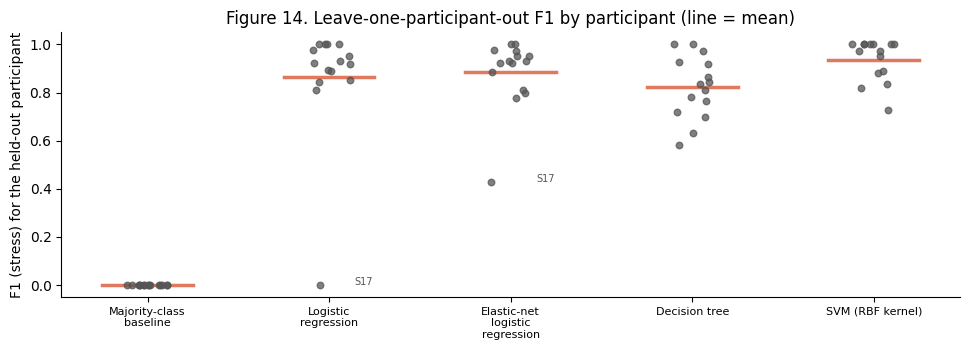

Best model by mean F1: SVM (RBF kernel) (0.937)


,predicted non-stress,predicted stress
true non-stress,703,10
true stress,25,277


In [28]:
per_participant_f1 = pd.DataFrame({name: per_fold.set_index("held out")["F1"] for name, (per_fold, _) in results.items()})

fig, ax = plt.subplots(figsize=(1.8 + 1.6 * len(results), 3.6))
rng = np.random.default_rng(1)
for k, name in enumerate(per_participant_f1.columns):
    vals = per_participant_f1[name]
    ax.scatter(np.full(len(vals), k) + rng.uniform(-0.12, 0.12, len(vals)), vals, s=22, color="#555", alpha=0.75, zorder=3)
    ax.plot([k - 0.25, k + 0.25], [vals.mean()] * 2, color="#e07a5f", lw=2.5)
    if name != "Majority-class baseline":                  # label participants a real model fails on
        for sid, v in vals[vals < 0.5].items():
            ax.annotate(sid, (k + 0.14, v), fontsize=7, color="#555")
ax.set_xticks(range(len(per_participant_f1.columns)),
              [textwrap.fill(n, 16) for n in per_participant_f1.columns], fontsize=8)
ax.set_ylabel("F1 (stress) for the held-out participant")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Figure 14. Leave-one-participant-out F1 by participant (line = mean)")
fig.tight_layout()
plots.save_fig(fig, "fig14_lopo_f1_by_participant", cfg)
plt.show()

# ---- best model on the pre-declared primary metric ---------------------------------------------
candidates = {n: r for n, r in results.items() if n != "Majority-class baseline"}
ranking = pd.DataFrame({n: {PRIMARY_METRIC: r[0][PRIMARY_METRIC].mean(), "balanced accuracy": r[0]["balanced accuracy"].mean()}
                        for n, r in candidates.items()}).T.sort_values([PRIMARY_METRIC, "balanced accuracy"], ascending=False)
BEST_MODEL = ranking.index[0]
print(f"Best model by mean {PRIMARY_METRIC}: {BEST_MODEL} ({ranking.iloc[0][PRIMARY_METRIC]:.3f})")

# Pooled confusion matrix of the best model's out-of-fold predictions
best_pred = (results[BEST_MODEL][1] >= 0.5).astype(int)
cm = pd.DataFrame(confusion_matrix(y_ml, best_pred), index=["true non-stress", "true stress"],
                  columns=["predicted non-stress", "predicted stress"])
display(cm)

**What the evaluation shows.** All four models clearly beat the majority-class baseline, which never predicts stress (70% accurate but F1 = 0, which is exactly why accuracy is not the primary metric). By the pre-declared rule, the **SVM (RBF kernel) is selected**: mean F1 **0.94 ± 0.09** on participants it has never seen (balanced accuracy 0.95, AUROC 0.99). Pooled over all held-out windows it detects 277 of 302 stress windows (92%) with 10 false alarms among 713 non-stress windows (1.4%). It is also the most consistent model: its lowest score is 0.73 (S15, who reported that the stress task did not feel stressful), and it scores 0.82 for **S17**, whom plain logistic regression misses completely (F1 = 0).

S17 explains most of the differences between models. S17 is the only participant whose wrist EDA fell under stress (Figure 10), and plain logistic regression leans on wrist EDA, so it labels all of S17's stress windows as non-stress. The elastic net (0.88 ± 0.14) beats plain logistic regression (0.87 ± 0.25) only because it partly rescues S17 (F1 0.43). For the other 14 participants the two linear models are almost identical. The SVM combines features non-linearly and recognizes S17's stress from the other signals.

The decision tree has the lowest mean F1 (0.82 ± 0.13) and AUROC (0.91). The tuned tree size varied widely between folds (depth 2 to 8), suggesting that a single tree is unstable with 14 training participants. Unlike the linear models, it never fails completely for one person.

**Caveat.** With 15 participants, the SVM's lead over the linear models comes mostly from one person (S17). It is the best model here, but the dataset is not sufficiently large to assert that any of the trained models will generalize to new participants. 

### Elastic Net Tuning Parameters 

Penalty chosen on all participants: {'C': 1e-05, 'l1_ratio': 0.0}
Largest raw coefficient in the all-participant fit: 3.48e-03 log-odds per SD


,relative weight (all participants),median relative weight (15 folds),kept in folds (of 15)
chest_eda_uS_bz,1.000,1.000,15
resp_interval_sd_s_bz,0.970,0.970,15
chest_acc_sd_g_bz,0.970,0.970,15
wrist_hr_bpm_bz,0.970,0.970,15
wrist_eda_uS_bz,0.960,0.950,15
wrist_temp_slope_C_per_min_bz,-0.660,-0.640,15
wrist_acc_sd_g_bz,0.500,0.490,15
wrist_temp_C_bz,-0.460,-0.440,15
chest_eda_slope_uS_per_min_bz,0.380,0.370,15
chest_rmssd_ms_bz,-0.300,-0.290,15


The all-participant elastic net keeps 12 of 12 features.
Order in which features enter the lasso as the penalty weakens (smallest C at which each coefficient is non-zero):


,C at entry
wrist_hr_bpm_bz,0.003
chest_eda_uS_bz,0.003
wrist_eda_uS_bz,0.003
resp_interval_sd_s_bz,0.003
chest_acc_sd_g_bz,0.003
wrist_temp_slope_C_per_min_bz,0.010
wrist_temp_C_bz,0.016
emg_rms_mV_bz,0.032
wrist_acc_sd_g_bz,0.044
chest_rmssd_ms_bz,0.052


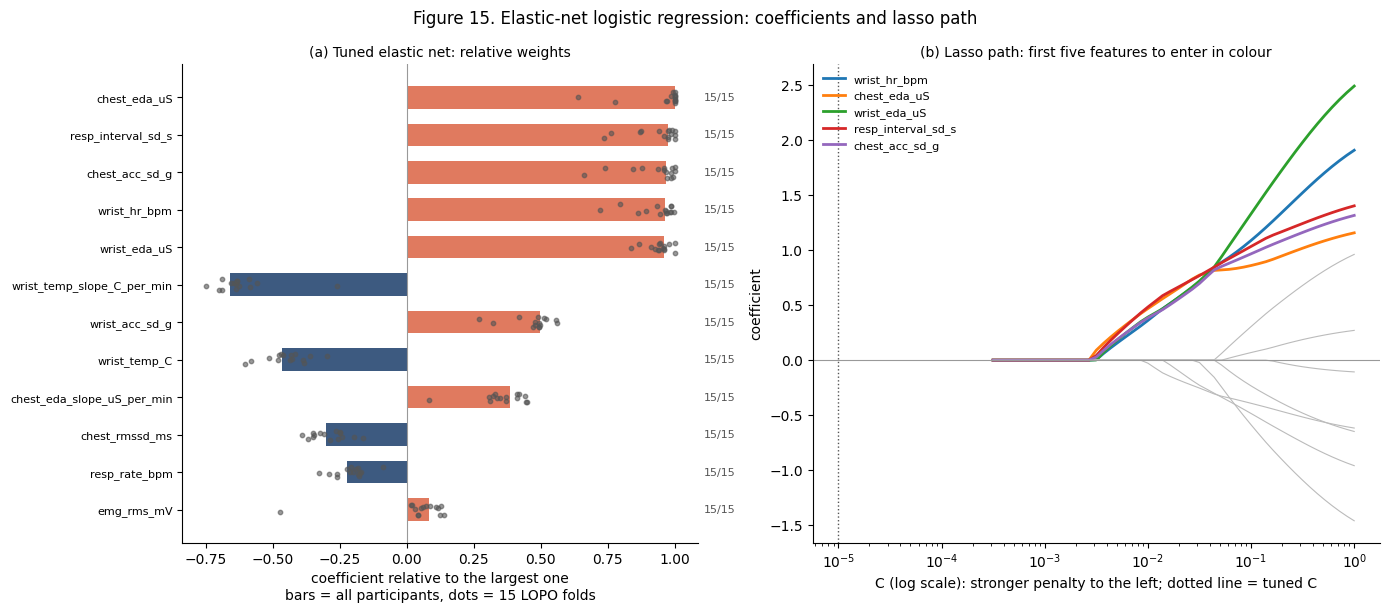

In [29]:
# ---- elastic net: which features are kept? ----------------------------------------------------
enet_all = clone(MODELS["Elastic-net logistic regression"]).fit(X_ml, y_ml, groups=groups_ml)
print("Penalty chosen on all participants:",
      {k.split("__")[-1]: v for k, v in enet_all.best_params_.items()})

# Heavy shrinkage makes the raw coefficients tiny, so each fit's coefficients are shown relative to its largest one
def relative(coefs):
    coefs = np.asarray(coefs, float)
    return coefs / np.abs(coefs).max()


enet_raw = enet_all.best_estimator_.named_steps["clf"].coef_[0]
print(f"Largest raw coefficient in the all-participant fit: {np.abs(enet_raw).max():.2e} log-odds per SD")
fold_raw = pd.DataFrame([m.best_estimator_.named_steps["clf"].coef_[0] for m in FOLD_MODELS["Elastic-net logistic regression"]],
                        columns=ML_FEATURES)
fold_rel = fold_raw.apply(relative, axis=1, result_type="broadcast")
enet_coefs = pd.DataFrame({
    "relative weight (all participants)": relative(enet_raw),
    "median relative weight (15 folds)": fold_rel.median(),
    "kept in folds (of 15)": (fold_raw.abs() > 1e-12).sum(),
}, index=ML_FEATURES).sort_values("relative weight (all participants)", key=np.abs, ascending=False)
display(enet_coefs.round(2))
n_kept = int((np.abs(enet_raw) > 1e-12).sum())
print(f"The all-participant elastic net keeps {n_kept} of {len(ML_FEATURES)} features.")

# Lasso path: refit with a pure L1 penalty at decreasing C to see the order in which features drop out
lasso = clone(MODELS["Elastic-net logistic regression"].estimator).set_params(clf__l1_ratio=1.0)
path_C = np.logspace(-3.5, 0, 50)
lasso_path = pd.DataFrame([clone(lasso).set_params(clf__C=C).fit(X_ml, y_ml).named_steps["clf"].coef_[0] for C in path_C],
                          index=path_C, columns=ML_FEATURES)
entry_C = (lasso_path.abs() > 1e-8).idxmax().where((lasso_path.abs() > 1e-8).any())   # smallest C at which a feature is in
print("Order in which features enter the lasso as the penalty weakens (smallest C at which each coefficient is non-zero):")
display(entry_C.sort_values().rename("C at entry").to_frame().round(4))

order = enet_coefs.index[::-1]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 0.4 * len(order) + 1.4), gridspec_kw={"width_ratios": [1, 1.1]})
coef = enet_coefs.loc[order, "relative weight (all participants)"]
ax.barh(range(len(order)), coef, color=np.where(coef > 0, "#e07a5f", "#3d5a80"), height=0.6)
for k, f in enumerate(order):
    ax.scatter(fold_rel[f], np.full(len(fold_rel), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(fold_rel)),
               s=10, color="#555", alpha=0.6, zorder=3)
    ax.annotate(f"{enet_coefs.loc[f, 'kept in folds (of 15)']}/15", (1.01, k), xycoords=("axes fraction", "data"),
                va="center", fontsize=8, color="#555")
ax.axvline(0, color="#999", lw=0.8)
ax.set_yticks(range(len(order)), [f.removesuffix("_bz") for f in order], fontsize=8)
ax.set_xlabel("coefficient relative to the largest one\nbars = all participants, dots = 15 LOPO folds")
ax.set_title("(a) Tuned elastic net: relative weights", fontsize=10)

top = entry_C.sort_values().index[:5]                                  # label the first five features to enter
for f in ML_FEATURES:
    ax2.plot(lasso_path.index, lasso_path[f], lw=2 if f in top else 0.8,
             color=None if f in top else "#bbb", label=f.removesuffix("_bz") if f in top else None)
ax2.set_xscale("log")
ax2.axhline(0, color="#999", lw=0.8)
ax2.axvline(enet_all.best_params_["clf__C"], color="#555", ls=":", lw=1)
ax2.set_xlabel("C (log scale): stronger penalty to the left; dotted line = tuned C")
ax2.set_ylabel("coefficient")
ax2.set_title("(b) Lasso path: first five features to enter in colour", fontsize=10)
ax2.legend(fontsize=8, frameon=False, loc="upper left")
fig.suptitle("Figure 15. Elastic-net logistic regression: coefficients and lasso path")
fig.tight_layout()
plots.save_fig(fig, "fig15_elastic_net_coefficients", cfg)
plt.show()


**What Figure 15 shows.** In 12 of the 15 training sets, and on all participants, the inner tuning chose a pure ridge penalty ($\rho = 0$) with the strongest penalty on the grid ($C = 10^{-5}$). So **the elastic net keeps all 12 features and selects none**: the data favoured shrinking every coefficient heavily over dropping features.


**Why this helps with S17.** Without much penalty the model leans hardest on wrist EDA: it has the largest coefficient at $C = 1$ (right end of panel b). The shrunk model spreads its weight over five signals, so one person whose EDA moves the wrong way is no longer automatically misclassified.

**Feature ranking.** The lasso path (b) gives the ranking that the tuned model did not. The same five features enter first and almost together, then wrist temperature slope and wrist temperature; respiration rate enters last. All four predictors chosen in advance for section 11.3 are among the first seven to enter.

### Tuned Decision Tree

Tree chosen on all participants: {'max_depth': 4, 'min_samples_leaf': 5}; depth 4, 13 leaves


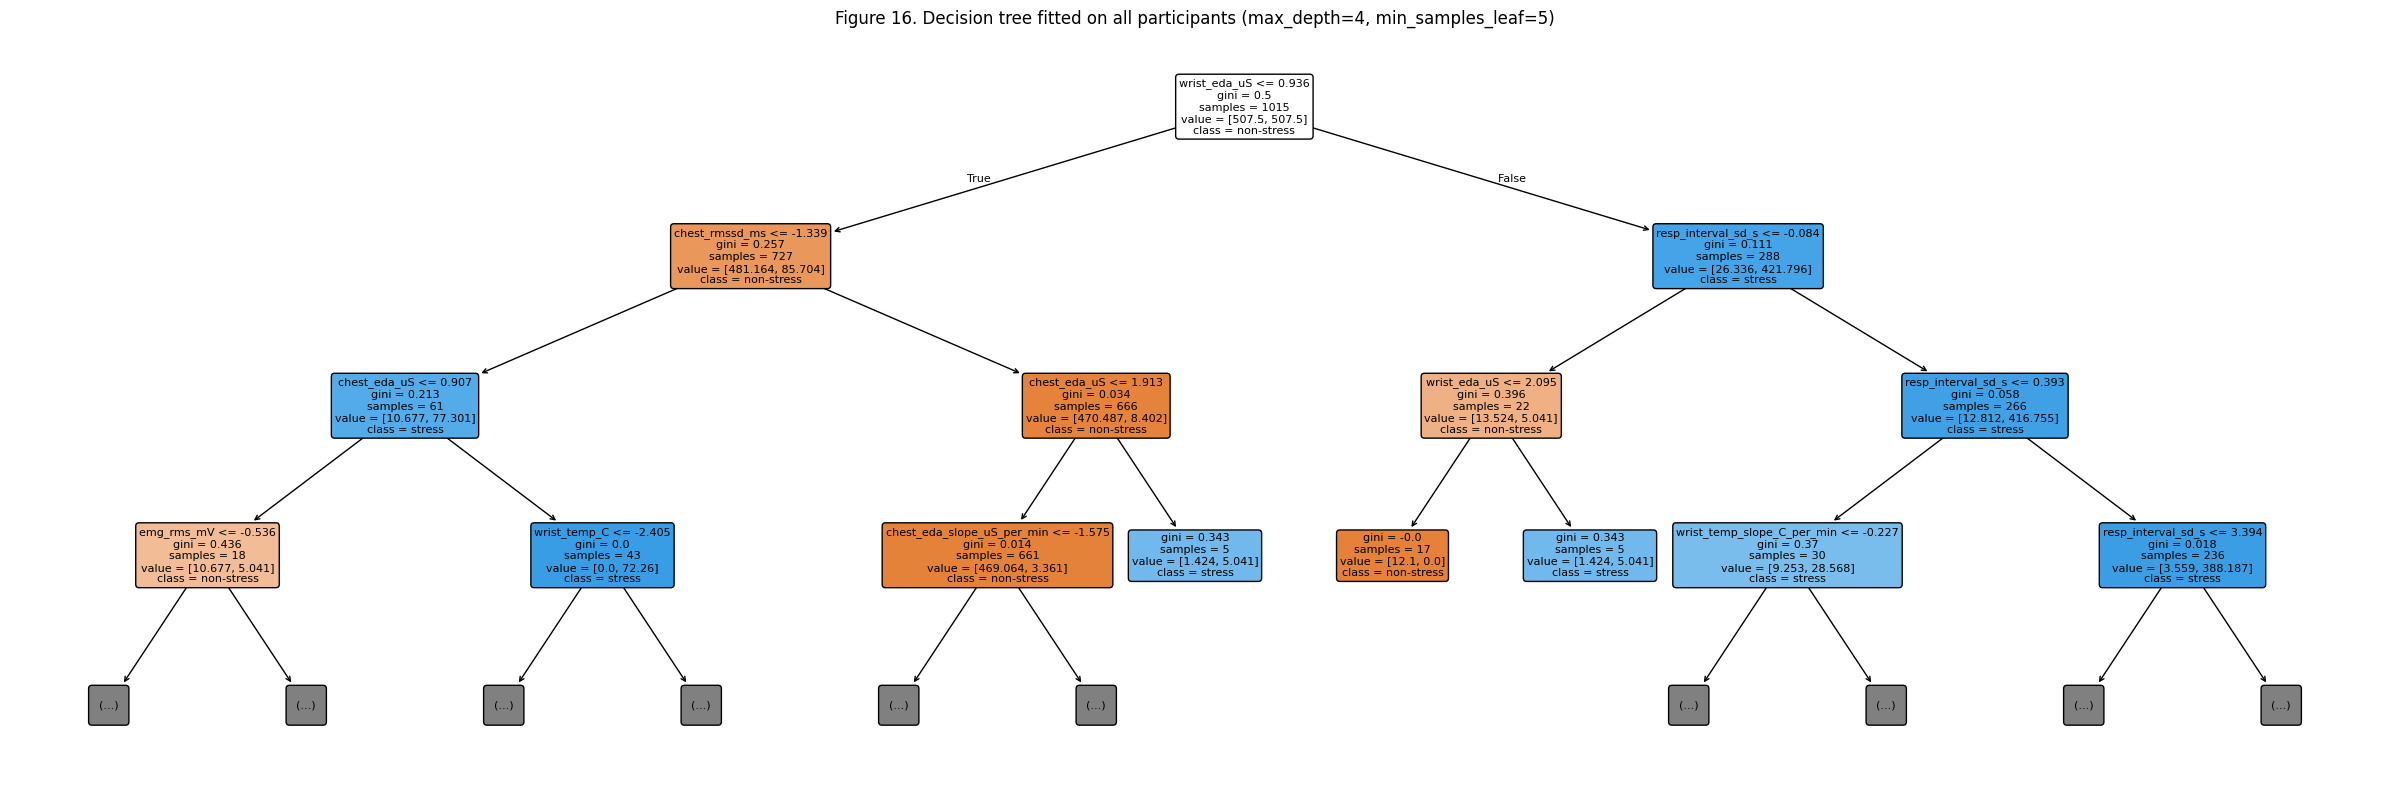

In [30]:
# ---- decision tree: the rules it learned -----------------------------------------------------
tree_all = clone(MODELS["Decision tree"]).fit(X_ml, y_ml, groups=groups_ml)
tree_params = {k.split("__")[-1]: v for k, v in tree_all.best_params_.items()}
tree_clf = tree_all.best_estimator_.named_steps["clf"]
print(f"Tree chosen on all participants: {tree_params}; depth {tree_clf.get_depth()}, {tree_clf.get_n_leaves()} leaves")

fig, ax = plt.subplots(figsize=(24, 8))
plot_tree(tree_clf, feature_names=[f.removesuffix("_bz") for f in ML_FEATURES], class_names=["non-stress", "stress"],
          filled=True, rounded=True, fontsize=8, max_depth=3, impurity=True, proportion=False, ax=ax)
ax.set_title(f"Figure 16. Decision tree fitted on all participants "
             f"(max_depth={tree_params['max_depth']}, min_samples_leaf={tree_params['min_samples_leaf']})",
             fontsize=12)
fig.tight_layout()
plots.save_fig(fig, "fig16_decision_tree", cfg)
plt.show()


**What Figure 16 shows.** The first split is on wrist EDA. Windows more than 0.94 SD above the person's resting skin conductance go right (288 windows, mostly stress), where breathing irregularity separates the remaining non-stress windows. On the left, where wrist EDA is not raised, the tree looks for a second route to stress: chest RMSSD more than 1.34 SD below rest (reduced heart-rate variability) together with raised chest EDA, a branch that leads to an almost purely stress node of 43 windows. This second route is how a tree can recognize stress windows like S17's, in which wrist EDA does not rise. The `value` counts are class-weighted (each stress window counts 1.68, each non-stress window 0.71), which is why both classes total 507.5 at the root. The deeper splits (grey boxes) are not drawn; they refine small groups of windows and change between folds.

**Figure 17** compares which features the two non-linear models rely on. For the decision tree, **Gini importance** is the total impurity reduction a feature produces across all its splits (averaged over the 15 fold trees; it sums to 1). The SVM has no coefficients, so its importance is measured by **permutation**: in each LOPO round, one feature of the *held-out* participant is shuffled and the drop in AUROC is recorded (5 shuffles per feature, averaged over the 15 participants). AUROC is used rather than F1 because it responds smoothly to shuffling, whereas F1 at a fixed threshold changes in coarse steps on a single person's ~68 windows.

,decision tree (Gini importance),SVM (drop in AUROC when shuffled)
wrist_eda_uS_bz,0.575,0.025
wrist_hr_bpm_bz,0.014,0.006
resp_interval_sd_s_bz,0.044,0.006
chest_rmssd_ms_bz,0.181,0.005
chest_acc_sd_g_bz,0.006,0.005
chest_eda_uS_bz,0.166,0.005
emg_rms_mV_bz,0.003,0.003
wrist_temp_slope_C_per_min_bz,0.005,0.003
wrist_acc_sd_g_bz,0.003,0.002
resp_rate_bpm_bz,0.000,0.001


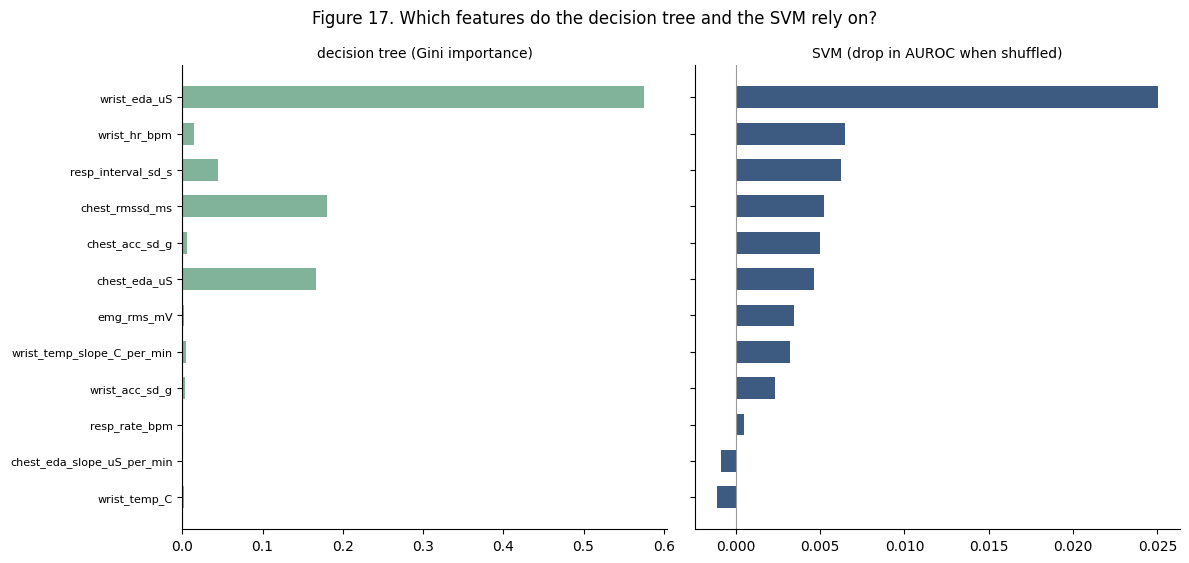

In [31]:
# ---- feature importance: decision tree (Gini) and SVM (permutation on held-out participants) ----
tree_importance = pd.DataFrame([m.best_estimator_.named_steps["clf"].feature_importances_
                                for m in FOLD_MODELS["Decision tree"]], columns=ML_FEATURES).mean()

svm_rows = []
splits = LeaveOneGroupOut().split(X_ml, y_ml, groups_ml)
for fitted, (_, test_idx) in zip(FOLD_MODELS["SVM (RBF kernel)"], splits):
    if y_ml.iloc[test_idx].nunique() < 2:
        continue
    pi = permutation_importance(fitted, X_ml.iloc[test_idx], y_ml.iloc[test_idx], scoring="roc_auc",
                                n_repeats=5, random_state=RANDOM_STATE)
    svm_rows.append(pi.importances_mean)
svm_importance = pd.DataFrame(svm_rows, columns=ML_FEATURES).mean()

importance = pd.DataFrame({"decision tree (Gini importance)": tree_importance,
                           "SVM (drop in AUROC when shuffled)": svm_importance})
display(importance.sort_values("SVM (drop in AUROC when shuffled)", ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 0.35 * len(ML_FEATURES) + 1.5), sharey=True)
order = importance["SVM (drop in AUROC when shuffled)"].sort_values().index
for ax, col, color in zip(axes, importance.columns, ["#81b29a", "#3d5a80"]):
    ax.barh(range(len(order)), importance.loc[order, col], color=color, height=0.6)
    ax.set_title(col, fontsize=10)
    ax.axvline(0, color="#999", lw=0.8)
axes[0].set_yticks(range(len(order)), [f.removesuffix("_bz") for f in order], fontsize=8)
fig.suptitle("Figure 17. Which features do the decision tree and the SVM rely on?")
fig.tight_layout()
plots.save_fig(fig, "fig17_feature_importance", cfg)
plt.show()


**What Figure 17 shows.** Both non-linear models rely most on wrist EDA, but in different ways. The tree concentrates its importance in three features (wrist EDA 0.58, chest RMSSD 0.18, chest EDA 0.17) and barely uses the rest: each split uses one feature, so correlated features compete and the losers get no credit. The SVM spreads its reliance more evenly. Shuffling wrist EDA for the held-out person lowers AUROC by 0.025, and shuffling wrist heart rate, breathing irregularity, chest RMSSD, chest movement or chest EDA lowers it by about 0.005 each. These drops are small because AUROC is already close to 1 and the remaining features can partly stand in for a shuffled one. That redundancy is also what makes the SVM robust to one person's unusual response. Shuffling wrist temperature or chest EDA slope makes no difference (the slightly negative values are noise).

**Across sections 11 and 12, the same picture emerges:** electrodermal activity, heart rate and heart-rate variability, and breathing pattern carry the stress signal, and models that combine several of them generalize best to new people.

## 13. Deep learning: multi-layer perceptron (MLP)

The last model is a neural network, following the course's M4B module. It is evaluated with the same `evaluate_lopo` function and the same leave-one-participant-out splits as the models in section 12, so the comparison is fair, and the final model is chosen from all five candidates at the end of this section.

### Architecture
A **multi-layer perceptron** has an input layer (one node per feature, here $p = 12$), one or more **hidden layers** of neurons with a non-linear activation, and an output layer. For binary classification with two hidden layers of sizes $h_1$ and $h_2$:

$$\text{Layer 1: } \mathbf{a}^{(1)} = \phi\left(\mathbf{W}^{(1)} \mathbf{x} + \mathbf{b}^{(1)}\right) \in \mathbb{R}^{h_1} \qquad \text{Layer 2: } \mathbf{a}^{(2)} = \phi\left(\mathbf{W}^{(2)} \mathbf{a}^{(1)} + \mathbf{b}^{(2)}\right) \in \mathbb{R}^{h_2}$$

$$\text{Output: } \hat{p} = \sigma\left(\mathbf{W}^{(3)} \mathbf{a}^{(2)} + b^{(3)}\right) = P(\text{stress} = 1 \mid \mathbf{x})$$

where $\phi$ is the hidden-layer activation (ReLU, $\phi(z) = \max(0, z)$) and $\sigma$ is the sigmoid. Passing $\mathbf{x}$ through these layers is **forward propagation**; the prediction is $\hat{y} = \mathbf{1}[\hat{p} \geq 0.5]$. With a single hidden layer the network is already a *universal approximator*: given enough neurons it can represent any continuous decision boundary. Logistic regression is the special case with no hidden layer.

### Training: loss, backpropagation and Adam
The network minimizes the same **binary cross-entropy** as logistic regression, plus an L2 penalty on the weights controlled by `alpha`:

$$\mathcal{L} = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log \hat{p}_i + (1 - y_i) \log(1 - \hat{p}_i) \right] + \frac{\alpha}{2n}\sum_{l}\|\mathbf{W}^{(l)}\|_2^2$$

**Backpropagation** applies the chain rule layer by layer, from the output back to the input, to get the gradient of the loss for every weight; at the output, $\partial \mathcal{L} / \partial z^{(3)} = \hat{p}_i - y_i$, the prediction error. The **Adam** optimizer then updates each weight with its own adaptive step size, using running averages of the gradient ($\hat{m}_t$) and of its square ($\hat{v}_t$):

$$\mathbf{w}_{t+1} = \mathbf{w}_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \cdot \hat{m}_t$$

| Setting | Meaning | Value used |
|---|---|---|
| Learning rate $\eta$ | Step size of each update | 0.001 (Adam default) |
| Batch size | Windows per gradient estimate (mini-batch) | 32 |
| Epochs | Full passes through the training data | up to 500, set by early stopping |
| `alpha` | L2 weight penalty | 0.0001 (course default) |

### Overfitting and early stopping
A network with ~10,000 weights can memorize ~950 training windows. **Early stopping** holds out 10% of the training windows, checks the score on them after each epoch, and stops when it has not improved for 20 epochs (`n_iter_no_change`). It is the main defence against overfitting here, together with the L2 penalty.

### Model
The course's MLP is used unchanged: two hidden layers of 128 and 64 ReLU neurons, Adam, `alpha = 0.0001`, batch size 32 and early stopping. Its settings are fixed rather than tuned, as in the course's baseline model, which also keeps **Run all** fast.

**Pipeline** (as in the course): imputation → Yeo–Johnson → standardization → MLP, all fitted inside each training fold. Neural networks are very sensitive to feature scale, so standardization is essential. The median imputer replaces the course's KNN imputer for consistency with the other models; the 12 features have no missing values in the saved table, but the imputer keeps the pipeline safe for uploaded tables.

**Two limitations.** (1) scikit-learn's `MLPClassifier` has no `class_weight` option, so unlike the other models the MLP does not up-weight the minority stress class. (2) The early-stopping validation windows are drawn at random from the training participants, so they come from the same people the network is training on. Early stopping therefore guards against memorizing individual windows but not against learning person-specific patterns. Neither affects the held-out participant, who is never seen during training.

In [32]:
# =============================================================================
# Section 13: MULTI-LAYER PERCEPTRON (course M4B-Section 14)
# =============================================================================
# Pipeline steps:
#   1. SimpleImputer    - fill the occasional missing value (median)
#   2. PowerTransformer - Yeo-Johnson normalization of skewed features
#   3. StandardScaler   - zero mean, unit variance (required for an MLP)
#   4. MLPClassifier    - feedforward neural network, ReLU hidden layers, sigmoid output
# =============================================================================

mlp_pipeline = Pipeline([
    ("imputer",     SimpleImputer(strategy="median")),
    ("transformer", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler",      StandardScaler()),
    ("clf",         MLPClassifier(
                        hidden_layer_sizes=(128, 64),   # two hidden layers
                        activation="relu",
                        solver="adam",
                        alpha=0.0001,                   # L2 regularization
                        batch_size=32,
                        learning_rate_init=0.001,
                        max_iter=500,
                        early_stopping=True,            # monitor a validation split
                        validation_fraction=0.1,        # 10% of training windows
                        n_iter_no_change=20,            # patience (epochs)
                        random_state=RANDOM_STATE)),
])

MLP_MODELS = {"MLP (course architecture)": mlp_pipeline}

for name, model in MLP_MODELS.items():
    start = time.perf_counter()
    FOLD_MODELS[name] = []
    results[name] = evaluate_lopo(model, X_ml, y_ml, groups_ml, fitted_models=FOLD_MODELS[name])
    print(f"{name}: evaluated in {time.perf_counter() - start:.0f} s")
MODELS.update(MLP_MODELS)

# Epochs trained before early stopping, across the 15 training sets
epochs = [(m.best_estimator_ if isinstance(m, GridSearchCV) else m).named_steps["clf"].n_iter_
          for m in FOLD_MODELS["MLP (course architecture)"]]
print(f"Course-architecture MLP: early stopping after {min(epochs)}-{max(epochs)} epochs (median {int(np.median(epochs))})")

display(summarize({n: results[n] for n in ["Logistic regression", "SVM (RBF kernel)", *MLP_MODELS]}))


MLP (course architecture): evaluated in 4 s
Course-architecture MLP: early stopping after 26-39 epochs (median 33)


,F1,recall,precision,balanced accuracy,accuracy,AUROC
Logistic regression,0.866 ± 0.247,0.874 ± 0.254,0.862 ± 0.250,0.921 ± 0.125,0.938 ± 0.080,0.982 ± 0.036
SVM (RBF kernel),0.937 ± 0.086,0.919 ± 0.139,0.969 ± 0.056,0.953 ± 0.069,0.966 ± 0.045,0.991 ± 0.016
MLP (course architecture),0.859 ± 0.250,0.841 ± 0.256,0.885 ± 0.258,0.910 ± 0.128,0.936 ± 0.083,0.973 ± 0.061


### 13.1 Training curve
**Figure 18** follows the course's training-curve plot for the course-architecture MLP, refitted once on all participants. The solid line is the training loss (cross-entropy) after each epoch; the dashed line is the accuracy on the 10% of windows held back for early stopping. Training stops when that validation score has not improved for 20 epochs (dotted line).

Architecture:   input (12) -> 128 -> 64 -> 1 (sigmoid)
Weights:        9,985 for 1,015 windows
Epochs trained: 33 (stopped after 20 epochs without improvement)
Best validation accuracy: 1.000


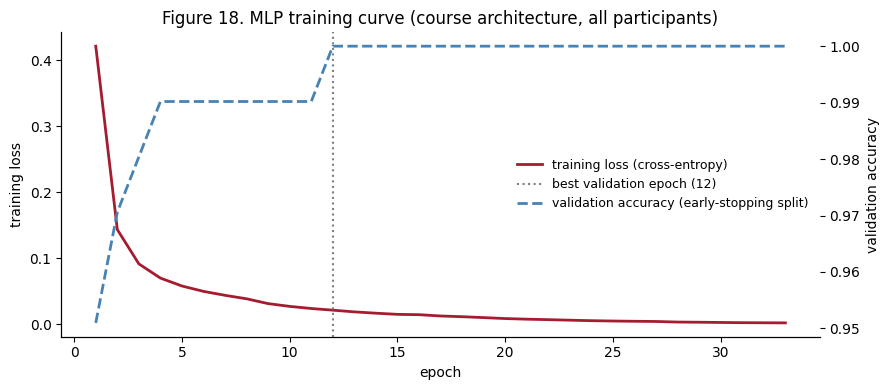

In [33]:
# =============================================================================
# MLP - TRAINING LOSS CURVE (course M4B-Section 14)
# =============================================================================
mlp_all = clone(mlp_pipeline).fit(X_ml, y_ml)
mlp_clf = mlp_all.named_steps["clf"]
print(f"Architecture:   input ({len(ML_FEATURES)}) -> 128 -> 64 -> 1 (sigmoid)")
print(f"Weights:        {sum(w.size + b.size for w, b in zip(mlp_clf.coefs_, mlp_clf.intercepts_)):,} for {len(X_ml):,} windows")
print(f"Epochs trained: {mlp_clf.n_iter_} (stopped after {mlp_clf.n_iter_no_change} epochs without improvement)")
print(f"Best validation accuracy: {mlp_clf.best_validation_score_:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(mlp_clf.loss_curve_) + 1), mlp_clf.loss_curve_, color="#A51C30", lw=2, label="training loss (cross-entropy)")
ax2 = ax.twinx()
ax2.plot(range(1, len(mlp_clf.validation_scores_) + 1), mlp_clf.validation_scores_, color="steelblue", lw=2, ls="--",
         label="validation accuracy (early-stopping split)")
best_epoch = int(np.argmax(mlp_clf.validation_scores_)) + 1
ax.axvline(best_epoch, color="gray", ls=":", lw=1.5, label=f"best validation epoch ({best_epoch})")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss")
ax2.set_ylabel("validation accuracy")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, [h.get_label() for h in handles], fontsize=9, loc="center right", frameon=False)
ax.set_title("Figure 18. MLP training curve (course architecture, all participants)")
fig.tight_layout()
plots.save_fig(fig, "fig18_mlp_training_curve", cfg)
plt.show()


**What Figure 18 shows.** The training loss falls steeply over the first three epochs and then keeps creeping towards zero: the network can fit the training windows almost perfectly. Validation accuracy reaches 1.000 at epoch 12, and training runs 20 more epochs without improvement before stopping at epoch 33. A perfect validation score is a concern because it likely means the model has overfit to the training data. The early-stopping windows are drawn at random from the same participants as the training windows, and with 50% overlap many of them are near-copies of training windows. 

### 13.2 Final model comparison and selection
**Figure 19** repeats Figure 14 with the MLP added: one dot per held-out participant, line = mean F1. The final model is selected by the same pre-declared rule as before: highest mean F1 across held-out participants, ties broken by balanced accuracy, with the majority-class baseline excluded.

,F1,recall,precision,balanced accuracy,accuracy,AUROC
Majority-class baseline,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.703 ± 0.011,0.500 ± 0.000
Logistic regression,0.866 ± 0.247,0.874 ± 0.254,0.862 ± 0.250,0.921 ± 0.125,0.938 ± 0.080,0.982 ± 0.036
Elastic-net logistic regression,0.884 ± 0.144,0.885 ± 0.200,0.919 ± 0.075,0.924 ± 0.097,0.939 ± 0.061,0.987 ± 0.019
Decision tree,0.823 ± 0.130,0.839 ± 0.176,0.831 ± 0.136,0.879 ± 0.094,0.895 ± 0.074,0.910 ± 0.091
SVM (RBF kernel),0.937 ± 0.086,0.919 ± 0.139,0.969 ± 0.056,0.953 ± 0.069,0.966 ± 0.045,0.991 ± 0.016
MLP (course architecture),0.859 ± 0.250,0.841 ± 0.256,0.885 ± 0.258,0.910 ± 0.128,0.936 ± 0.083,0.973 ± 0.061


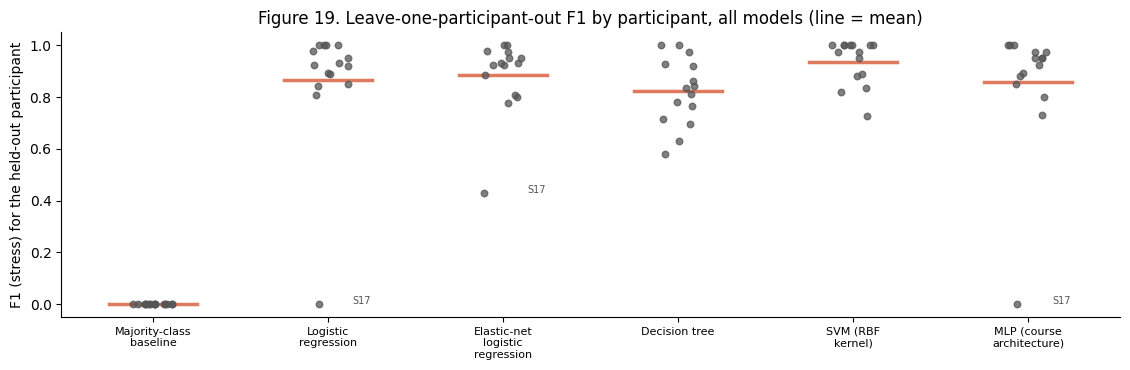

,F1,balanced accuracy
SVM (RBF kernel),0.937,0.953
Elastic-net logistic regression,0.884,0.924
Logistic regression,0.866,0.921
MLP (course architecture),0.859,0.910
Decision tree,0.823,0.879


Final model by mean F1: SVM (RBF kernel) (0.937)


,predicted non-stress,predicted stress
true non-stress,703,10
true stress,25,277


In [34]:
display(summarize(results))

per_participant_f1 = pd.DataFrame({name: per_fold.set_index("held out")["F1"] for name, (per_fold, _) in results.items()})
fig, ax = plt.subplots(figsize=(1.8 + 1.6 * len(results), 3.8))
rng = np.random.default_rng(1)
for k, name in enumerate(per_participant_f1.columns):
    vals = per_participant_f1[name]
    ax.scatter(np.full(len(vals), k) + rng.uniform(-0.12, 0.12, len(vals)), vals, s=22, color="#555", alpha=0.75, zorder=3)
    ax.plot([k - 0.25, k + 0.25], [vals.mean()] * 2, color="#e07a5f", lw=2.5)
    if name != "Majority-class baseline":                  # label participants a real model fails on
        for sid, v in vals[vals < 0.5].items():
            ax.annotate(sid, (k + 0.14, v), fontsize=7, color="#555")
ax.set_xticks(range(len(per_participant_f1.columns)),
              [textwrap.fill(n, 14) for n in per_participant_f1.columns], fontsize=8)
ax.set_ylabel("F1 (stress) for the held-out participant")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Figure 19. Leave-one-participant-out F1 by participant, all models (line = mean)")
fig.tight_layout()
plots.save_fig(fig, "fig19_lopo_f1_all_models", cfg)
plt.show()

# ---- final model on the pre-declared primary metric -----------------------------------------------
candidates = {n: r for n, r in results.items() if n != "Majority-class baseline"}
ranking = pd.DataFrame({n: {PRIMARY_METRIC: r[0][PRIMARY_METRIC].mean(), "balanced accuracy": r[0]["balanced accuracy"].mean()}
                        for n, r in candidates.items()}).T.sort_values([PRIMARY_METRIC, "balanced accuracy"], ascending=False)
display(ranking.round(3))
BEST_MODEL = ranking.index[0]
print(f"Final model by mean {PRIMARY_METRIC}: {BEST_MODEL} ({ranking.iloc[0][PRIMARY_METRIC]:.3f})")

best_pred = (results[BEST_MODEL][1] >= 0.5).astype(int)
display(pd.DataFrame(confusion_matrix(y_ml, best_pred), index=["true non-stress", "true stress"],
                     columns=["predicted non-stress", "predicted stress"]))


**What the MLP results show.** The course-architecture MLP (mean F1 0.86 ± 0.25) performs  similarly to baseline logistic regression model and struggles to classify stress in participant S17. With about 10,000 weights for about 950 training windows, and an early-stopping check that only sees the training participants (Figure 18), it learns the dominant pattern of the 14 training people, led by rising wrist EDA, and has no way to recognize a person whose skin conductance moves the other way.

**Final model.** By the pre-declared rule, the **SVM (RBF kernel)** remains the final model: mean F1 0.94 ± 0.09 and balanced accuracy 0.95, detecting 277 of 302 stress windows with 10 false alarms among 713 non-stress windows. It is the only model with no participant below 0.7. As before, its lead over the next models rests mainly on one participant (S17), so it is the best model on these data rather than one shown to be reliably better for new people.

**Why deep learning does not win here.** With about 1,000 windows from 15 people and 12 hand-crafted features, this dataset is not a strong candiate for applying MLP. A better application would be applying MLP on a larger dataset of raw signal data. 

### 13.3 Confusion matrices
**Figure 20** shows a confusion matrix for each model, using the course's `make_confusion_matrix` function. Each cell gives the number of windows and their share of all 1,015 windows: top left = calm windows correctly called non-stress (true negatives), top right = false alarms (false positives), bottom left = missed stress windows (false negatives), bottom right = stress windows detected (true positives). A classification report with precision, recall and F1 for each class follows each matrix.

The function therefore takes these **out-of-fold** predictions (`results[name][1]`, thresholded at 0.5) instead of a fitted model, so every number is still a prediction for a person the model never saw. Predicting with a model fitted on all participants would score it on its own training data and overstate performance. 

Logistic regression (out-of-fold predictions, all 1,015 windows)


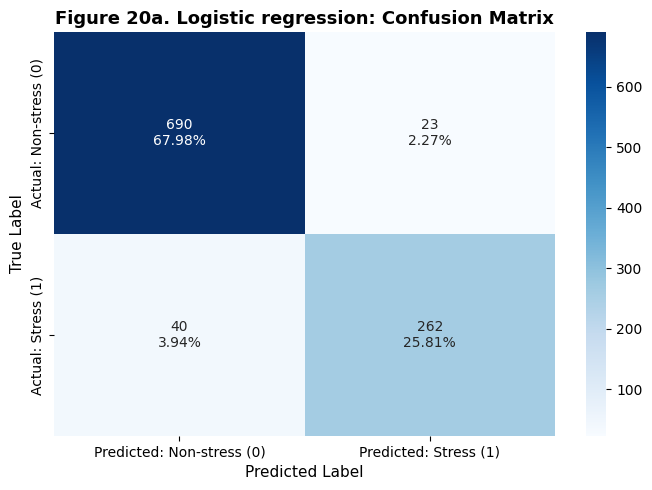


Classification Report:
              precision    recall  f1-score   support

  Non-stress       0.95      0.97      0.96       713
      Stress       0.92      0.87      0.89       302

    accuracy                           0.94      1015
   macro avg       0.93      0.92      0.92      1015
weighted avg       0.94      0.94      0.94      1015

Elastic-net logistic regression (out-of-fold predictions, all 1,015 windows)


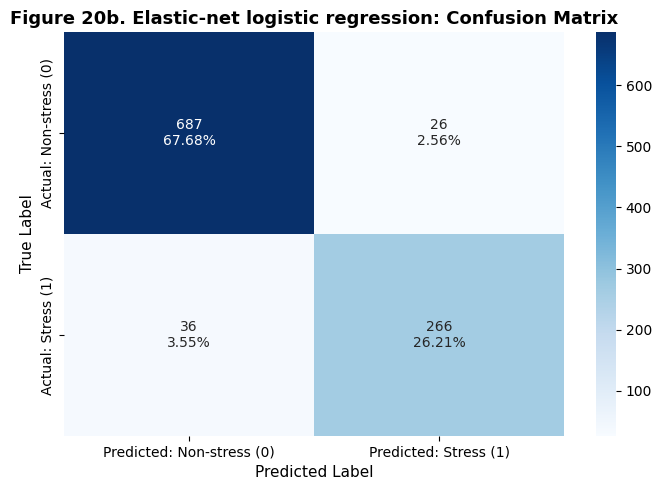


Classification Report:
              precision    recall  f1-score   support

  Non-stress       0.95      0.96      0.96       713
      Stress       0.91      0.88      0.90       302

    accuracy                           0.94      1015
   macro avg       0.93      0.92      0.93      1015
weighted avg       0.94      0.94      0.94      1015

Decision tree (out-of-fold predictions, all 1,015 windows)


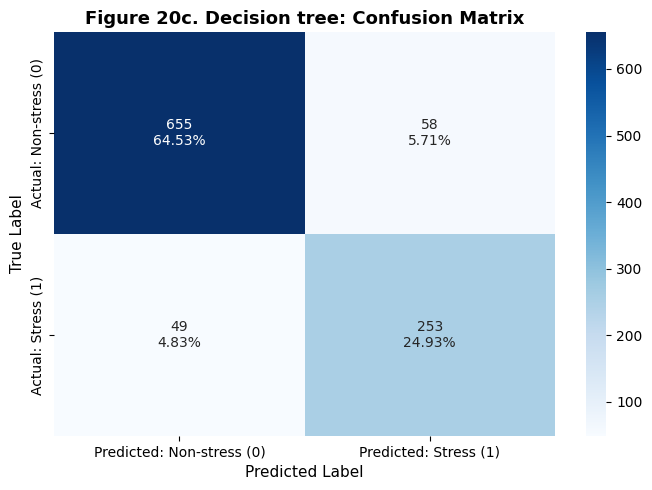


Classification Report:
              precision    recall  f1-score   support

  Non-stress       0.93      0.92      0.92       713
      Stress       0.81      0.84      0.83       302

    accuracy                           0.89      1015
   macro avg       0.87      0.88      0.87      1015
weighted avg       0.90      0.89      0.90      1015

SVM (RBF kernel) (out-of-fold predictions, all 1,015 windows)


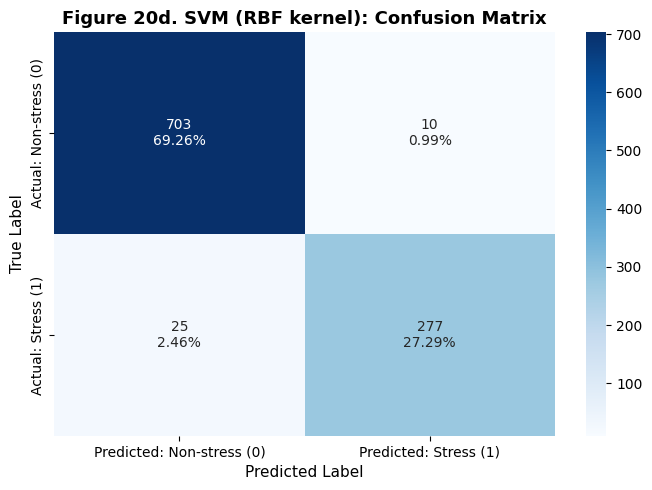


Classification Report:
              precision    recall  f1-score   support

  Non-stress       0.97      0.99      0.98       713
      Stress       0.97      0.92      0.94       302

    accuracy                           0.97      1015
   macro avg       0.97      0.95      0.96      1015
weighted avg       0.97      0.97      0.97      1015

MLP (course architecture) (out-of-fold predictions, all 1,015 windows)


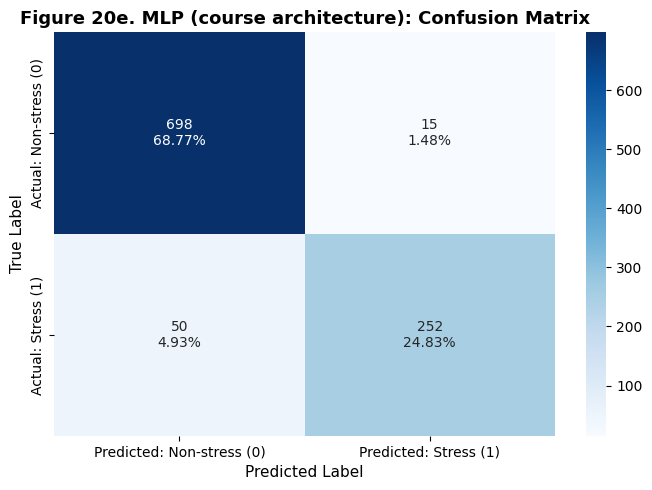


Classification Report:
              precision    recall  f1-score   support

  Non-stress       0.93      0.98      0.96       713
      Stress       0.94      0.83      0.89       302

    accuracy                           0.94      1015
   macro avg       0.94      0.91      0.92      1015
weighted avg       0.94      0.94      0.93      1015



In [35]:
# =============================================================================
# CONFUSION MATRICES (course function, adapted to out-of-fold LOPO predictions)
# =============================================================================
CLASS_NAMES = ["Non-stress", "Stress"]


def make_confusion_matrix(y_actual, y_prob, title="Confusion Matrix", threshold=0.5, fig_name=None):
    """
    Styled confusion matrix with counts and percentages, followed by a classification report.

    Parameters
    ----------
    y_actual  : true class labels (0 = non-stress, 1 = stress)
    y_prob    : out-of-fold stress probabilities from evaluate_lopo (one per window)
    title     : plot title
    threshold : probability at or above which a window is called stress
    fig_name  : file name for plots.save_fig (optional)
    """
    if len(y_actual) != len(y_prob) or pd.isna(y_prob).any():
        raise ValueError("y_prob must hold one out-of-fold probability for every window")
    y_predict = (np.asarray(y_prob) >= threshold).astype(int)
    cm = confusion_matrix(y_actual, y_predict, labels=[0, 1])

    group_counts      = [f"{v:0.0f}" for v in cm.flatten()]
    group_percentages = [f"{v:.2%}"  for v in cm.flatten() / np.sum(cm)]
    labels = np.array([f"{c}\n{p}" for c, p in
                       zip(group_counts, group_percentages)]).reshape(2, 2)

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="Blues",
        xticklabels=["Predicted: Non-stress (0)", "Predicted: Stress (1)"],
        yticklabels=["Actual: Non-stress (0)",    "Actual: Stress (1)"],
        ax=ax
    )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel("True Label", fontsize=11)
    ax.set_xlabel("Predicted Label", fontsize=11)
    plt.tight_layout()
    if fig_name:
        plots.save_fig(fig, fig_name, cfg)
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_actual, y_predict, labels=[0, 1],
                                target_names=CLASS_NAMES, zero_division=0))


letters = iter("abcdefghijklmnopqrstuvwxyz")
for name, (_, oof_prob) in results.items():
    if name == "Majority-class baseline":
        continue
    letter = next(letters)
    print(f"{name} (out-of-fold predictions, all {len(y_ml):,} windows)")
    make_confusion_matrix(y_ml, oof_prob, title=f"Figure 20{letter}. {name}: Confusion Matrix",
                          fig_name=f"fig20{letter}_confusion_{name.split(' (')[0].lower().replace(' ', '_').replace('-', '_')}")


### 13.4 ROC curves
**Figure 21** overlays the ROC curve of every model, following the course's plot. Each curve shows, as the probability threshold for calling a window "stress" moves from 1 down to 0, the share of stress windows caught (true positive rate, recall) against the share of calm windows wrongly flagged (false positive rate, 1 − specificity). A curve hugging the top-left corner is better; the dashed diagonal is a classifier that guesses. As with the confusion matrices, the curves use the **out-of-fold** probabilities, so every point describes performance on participants the model never saw.

The AUC in the legend is computed on all 1,015 windows pooled together, so it differs slightly from the mean per-participant AUROC in the tables above: pooling also rewards a model for ranking one person's windows against another person's, and a threshold that suits one person may not suit the next.

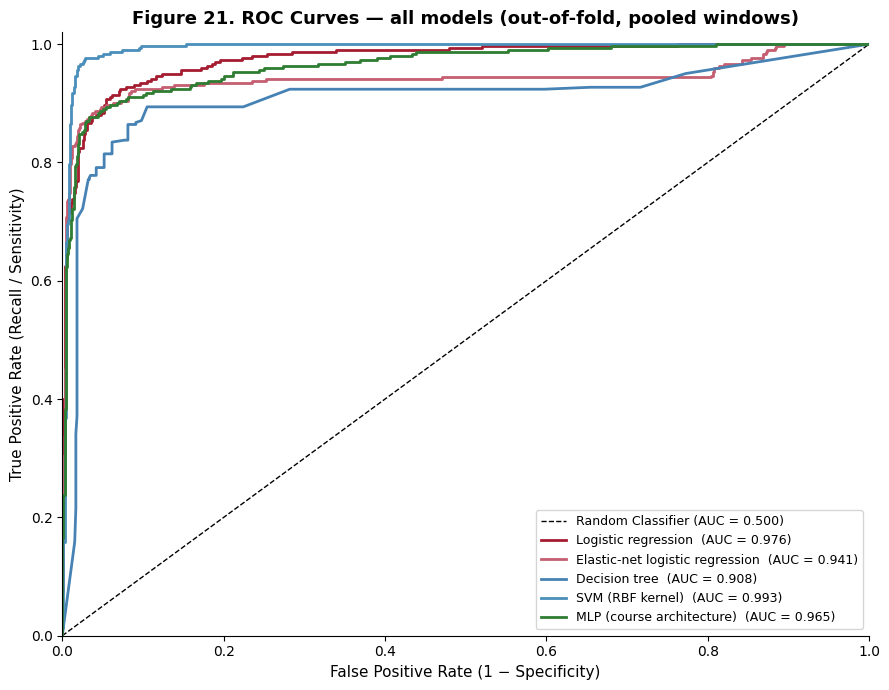

In [36]:
# =============================================================================
# ROC CURVES - ALL MODELS (course plot, out-of-fold LOPO probabilities)
# =============================================================================
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random Classifier (AUC = 0.500)")

colors = ["#A51C30", "#C45E70", "steelblue", "#4A8EBA", "#2E7D32", "#6ABF69"]
roc_models = {name: r for name, r in results.items() if name != "Majority-class baseline"}

for (model_name, (_, y_scores)), color in zip(roc_models.items(), colors):
    fpr, tpr, _ = roc_curve(y_ml, y_scores)
    auc = roc_auc_score(y_ml, y_scores)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{model_name}  (AUC = {auc:.3f})")

ax.set_xlabel("False Positive Rate (1 − Specificity)", fontsize=11)
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=11)
ax.set_title("Figure 21. ROC Curves — all models (out-of-fold, pooled windows)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="lower right")
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plots.save_fig(fig, "fig21_roc_curves", cfg)
plt.show()


**What Figure 21 shows.** The SVM's curve lies above all the others (pooled AUC 0.993): it catches about 97% of stress windows before 5% of calm windows are flagged. Logistic regression (0.976) and the MLP (0.965) follow. The decision tree is lowest (0.908), and its curve is stepped because a tree can only output as many distinct probabilities as it has leaves.

## 14. Data quality notes
- **Participant-specific problems.** Chest temperature is excluded for S2 and S17 (sensor not fully attached). S6 and S15 reported the stress task was not really stressful or did not believe it, and S8 and S16 felt cold in the stress room, which confounds skin temperature.
- **Signal vs. noise.** Chest and wrist both measure heart rate, so their disagreement (`flag_hr_disagree`) is a per-window check on wrist motion artifact, most likely during the stress task's speech when participants stand and gesture. Some stress windows show chest HR far above wrist HR (e.g., S11), suggesting the ECG detector also counts T-waves while the participant talks.
- **Movement and speech confounds.** The stress task has participants stand and talk, so movement and breathing irregularity rise partly for mechanical reasons. They will help a classifier on WESAD but may not transfer to stress experienced while sitting still.
- **Class imbalance.** About 30% of usable windows are stress, so accuracy alone would be misleading.
- **Window dependence.** Windows overlap by 50% and come from only 15 people. Evaluation must hold out whole participants, and p-values that treat windows as independent are too small; section 11.3 therefore repeats its regression on non-overlapping windows.
- **No wrist HRV.** RMSSD from the 64 Hz wrist pulse came out at 170–350 ms against about 50 ms from the ECG, so it was left out.

## 15. Summary and next steps
- **Pipeline.** Raw chest and wrist recordings from 15 participants become 1,015 validated, quality-flagged 60-second windows with 15 predictors; the notebook also accepts a user's own feature table in the same format and adapts its analysis to it.
- **Distributions.** Raw features are mostly right-skewed and dominated by differences between people; baseline normalization removes most of both, leaving only the movement features skewed enough to need a Yeo–Johnson transformation in linear models.
- **Which signals change under stress.** At the participant level, heart rate (chest and wrist), skin conductance responses, breathing irregularity and chest movement rise in all 15 participants and EDA in 14 of 15 (Wilcoxon signed-rank and sign tests, significant after correction); breathing rate, EMG and RMSSD show no consistent change.
- **Which signals predict stress independently.** In a conditional (fixed-effects) logistic regression that compares each participant only with themselves, wrist heart rate (OR 15 per SD), wrist EDA (OR 14) and breathing irregularity (OR 4.5) each independently predict a stress window, and so does cooler wrist temperature (OR 0.38, the weakest and a curved relationship). All four remain significant on non-overlapping windows. Because windows within a person are not independent, the p-values are approximate; the size and consistency of the effects carry the conclusion.
- **Prediction on new people.** Under leave-one-participant-out validation, with tuning nested inside each training set, the RBF-kernel SVM is the final model (mean F1 0.94 ± 0.09; 92% of stress windows detected with 1.4% false alarms), ahead of elastic-net logistic regression (0.88), plain logistic regression (0.87), the multi-layer perceptron (0.86) and a decision tree (0.82); the majority-class baseline scores 0. The SVM is the only model that works well for S17, whose skin conductance fell under stress; with 15 participants its lead rests largely on that one person.
- **What the models use.** The elastic net keeps all 12 features and spreads weight evenly over EDA, heart rate, breathing irregularity and movement rather than selecting a few; the decision tree and SVM rely most on wrist EDA, backed by heart-rate variability and chest EDA.
- **Deep learning.** The multi-layer perceptron (course architecture) does not beat the simpler models and fails on S17 like logistic regression. With ~1,000 windows and 12 hand-crafted features there is little for a neural network to add.
- **Next:** consider a spline term for wrist temperature; and, for a deployed device, a short personal calibration period, since person-level failures such as S17's cannot be fixed by more data from other people.